# **ACADEMY**

## **Projet: Analysez des données de systèmes éducatifs.**

### **Fil conducteur:**
- Le fil conducteur du projet est : passer des données éducatives à une présélection de marchés, puis préciser ce qu’il faut vérifier avant une implantation suivant le tableau ci-dessous:

| Étape | Question à laquelle répondre | Travail à présenter | Message à retenir |
|---|---|---|---|
| **1. Comprendre la demande de Mark** | Où academy pourrait-elle développer ses formations pour les lycéens et étudiants ? | Public cible, expansion internationale et évolution du potentiel. | Nous cherchons des marchés à explorer en priorité. |
| **2. Comprendre les données** | Quelles informations les cinq fichiers apportent-ils ? | Rôle des fichiers, dimensions, unités d’observation et clés de liaison. | Les données décrivent l’éducation et le public potentiel. |
| **3. Vérifier leur qualité** | Peut-on comparer les pays correctement ? | Doublons, valeurs manquantes, colonnes vides et exclusion des agrégats géographiques. | Un référentiel cohérent est nécessaire avant toute comparaison. |
| **4. Réduire le périmètre métier** | Quelles données répondent réellement au besoin d’academy ? | Catégories pertinentes, public lycée–université, période historique et projections séparées. | Tous les indicateurs éducatifs ne sont pas utiles au projet. |
| **5. Sélectionner les indicateurs exploitables** | Quels indicateurs sont pertinents et suffisamment renseignés ? | Couverture par année, indicateur et pays ; sélection de quinze indicateurs au maximum. | Il faut équilibrer pertinence métier et disponibilité. |
| **6. Construire une comparaison fiable** | Comment résumer les données sans compter plusieurs fois le même signal ? | Tableau pays–indicateurs, agrégation des années, Pearson et Spearman, réduction des redondances. | La comparaison repose sur des critères documentés et complémentaires. |
| **7. Identifier les pays à approfondir** | Quels pays ressortent selon les critères retenus ? | Distributions, top 5 par indicateur, fréquence d’apparition et contrôle de la couverture. | La liste obtenue est une présélection, sensible aux hypothèses. |
| **8. Conseiller Mark** | Que peut-on décider maintenant et que faut-il vérifier ensuite ? | Limites, actualisation, Internet, langues, capacité à payer, concurrence et pilote. | Les données orientent l’étude ; une validation commerciale doit suivre. |

### **Conseils:**
- Pour un premier projet, il est important de commencer à coder via notebook avec les méthodes Pandas et une visualisation des graphiques via Seaborn et Plotly.


## **Analyse fonctionnelle**

- Ce schéma formalise le besoin auquel répond l’analyse exploratoire : aider Mark et la direction d’academy à identifier les pays à étudier pour leur expansion internationale.
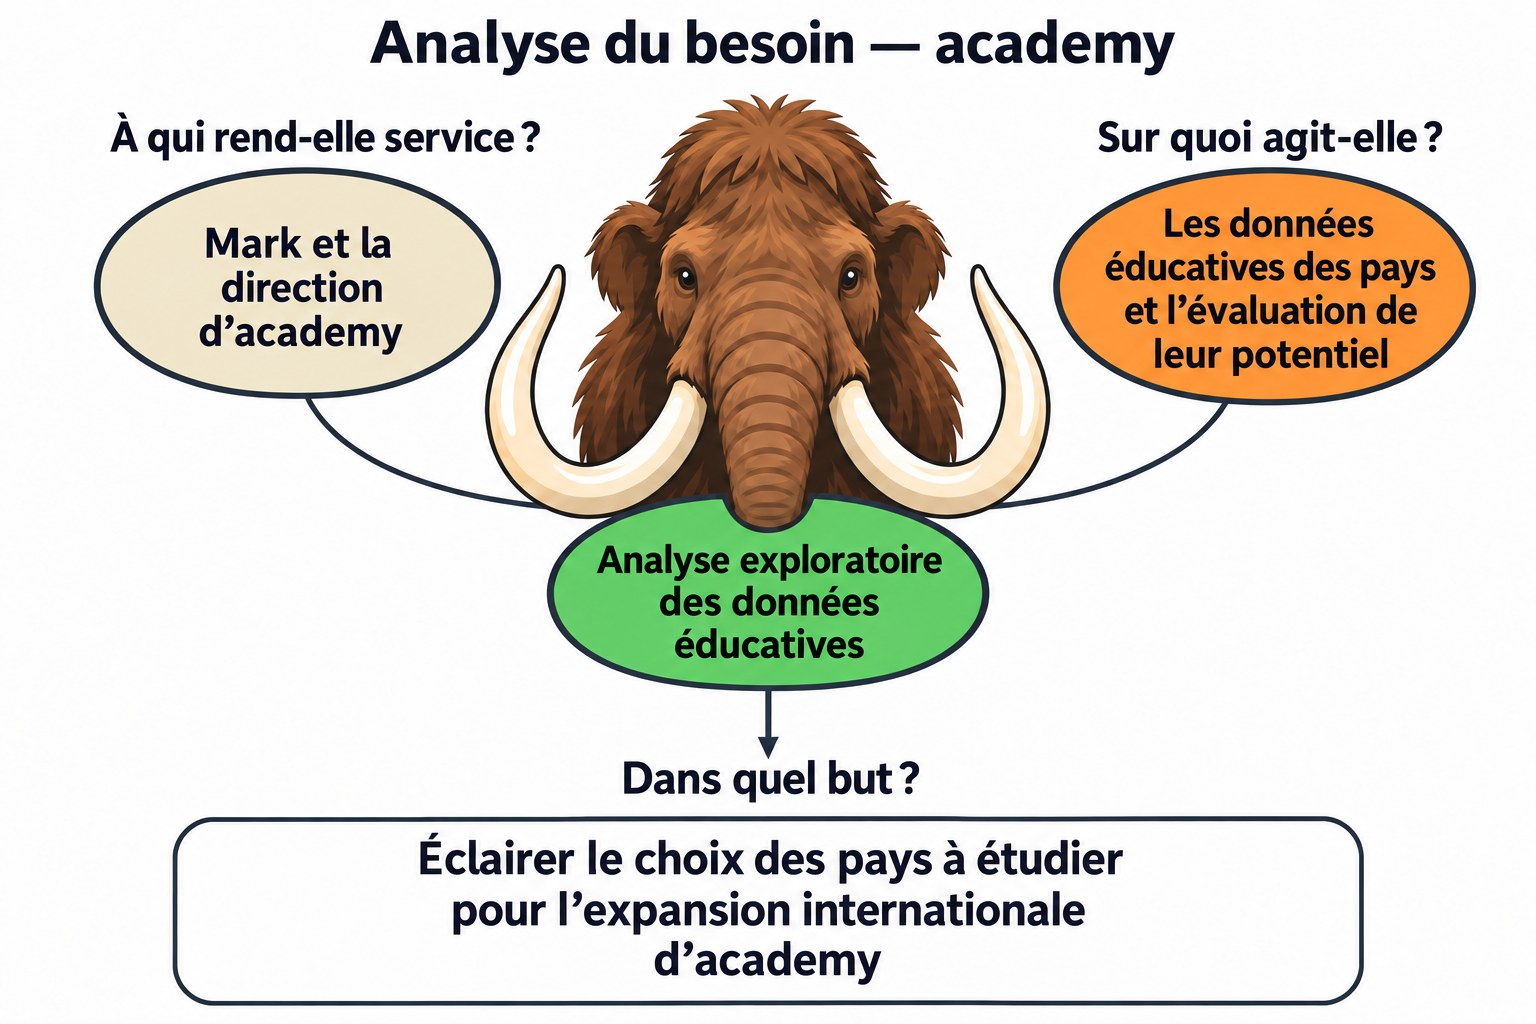

| Question | Application au projet |
|---|---|
| **À qui le projet rend-il service ?** | À Mark et à la direction d’academy, qui préparent l’expansion internationale de l’entreprise. |
| **Sur quoi agit-il ?** | Sur les données éducatives disponibles, transformées en informations comparables sur les pays et leur public potentiel de lycéens et d’étudiants. |
| **Dans quel but ?** | Évaluer si ces données peuvent éclairer la réflexion stratégique, identifier des pays à approfondir et explorer l’évolution du public potentiel. |

## **Expression du besoin**

- Permettre à Mark et à la direction d’academy d’évaluer, à partir des données éducatives disponibles, le potentiel de différents pays pour leurs formations en ligne destinées aux lycéens et aux étudiants, afin d’orienter les études préalables à une expansion internationale.

## **Validation du besoin**

| Question de validation | Réponse |
|---|---|
| **Pourquoi ce besoin existe-t-il ?** | Academy souhaite se développer à l’international et doit réduire l’incertitude sur les marchés à explorer. |
| **Qu’est-ce qui pourrait le faire évoluer ?** | Un changement de public cible, d’offre, de modèle économique ou de stratégie géographique. |
| **Qu’est-ce qui pourrait le faire disparaître ?** | L’abandon du projet d’expansion ou l’existence d’une étude suffisamment récente et complète répondant déjà à la demande. |

## Partie 0: Préparation de l'environnement.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display, Markdown
import gc
import textwrap

# Les seules données externes requises sont les cinq CSV EdStats.
noms_fichiers = {
    "EdStatsCountry": "EdStatsCountry.csv",
    "EdStatsCountry-Series": "EdStatsCountry-Series.csv",
    "EdStatsSeries": "EdStatsSeries.csv",
    "EdStatsFootNote": "EdStatsFootNote.csv",
    "EdStatsData": "EdStatsData.csv"
}
repertoire_donnees = Path.cwd()
display(pd.DataFrame({"jeu": list(noms_fichiers),
                      "fichier utilisé": list(noms_fichiers.values())}))


,jeu,fichier utilisé
0,EdStatsCountry,EdStatsCountry.csv
1,EdStatsCountry-Series,EdStatsCountry-Series.csv
2,EdStatsSeries,EdStatsSeries.csv
3,EdStatsFootNote,EdStatsFootNote.csv
4,EdStatsData,EdStatsData.csv


## Partie 1:

## Instructions et résultats attendus: 
1. Avoir chargé les données;
2. Visualiser dans un Jupyter Notebook les premières lignes des cinq fichiers en utilisant Pandas.

### Etape 1: Charger les données dans votre Notebook.

Les cinq fichiers ont été chargés dans des DataFrames Pandas.
L’affichage des premières lignes avec `head()` permet de vérifier
leur structure, les noms des colonnes et la nature des informations.

Les fichiers ont des rôles complémentaires :
- Country décrit les entités géographiques ;
- Series décrit les indicateurs ;
- Data contient leurs valeurs par pays et par année ;
- Country-Series apporte des informations propres à certains
  couples pays–indicateur ;
- FootNote apporte des précisions sur certaines valeurs.

Cette première lecture permet d’identifier les clés qui serviront
à relier les jeux de données.

#### 1. Chargement des 5 jeux de données.

In [2]:
chemins_csv = {nom: repertoire_donnees / fichier
               for nom, fichier in noms_fichiers.items()}
absents = [chemin.name for chemin in chemins_csv.values() if not chemin.is_file()]
if absents:
    raise FileNotFoundError(
        "Placer les cinq vrais CSV dans le dossier du notebook. "
        f"Fichiers absents : {absents}. Les fichiers au contenu CSV doivent porter l'extension .csv."
    )
colonnes_attendues = {
    "EdStatsCountry": ["Country Code", "Short Name", "Region", "Income Group"],
    "EdStatsCountry-Series": ["CountryCode", "SeriesCode"],
    "EdStatsSeries": ["Series Code", "Indicator Name", "Topic"],
    "EdStatsFootNote": ["CountryCode", "SeriesCode", "Year", "DESCRIPTION"],
    "EdStatsData": ["Country Code", "Country Name", "Indicator Code", "Indicator Name"]
}
fichiers = {}
for nom, chemin in chemins_csv.items():
    table = pd.read_csv(chemin, encoding="utf-8-sig", low_memory=False)
    table.columns = table.columns.astype(str).str.strip()
    if not table.columns.is_unique:
        raise ValueError(f"{nom} : noms de colonnes répétés après normalisation.")
    manquantes = set(colonnes_attendues[nom]) - set(table.columns)
    if manquantes:
        raise ValueError(f"{nom} : colonnes absentes {sorted(manquantes)}. "
                         "Vérifier le fichier d'origine et son séparateur, sans ignorer les lignes erronées.")
    fichiers[nom] = table
country = fichiers["EdStatsCountry"]
country_series = fichiers["EdStatsCountry-Series"]
series = fichiers["EdStatsSeries"]
footnote = fichiers["EdStatsFootNote"]
data = fichiers["EdStatsData"]
print("Chargement des cinq CSV terminé.")


Chargement des cinq CSV terminé.


#### 2. Visualiser les premières lignes des 5 fichiers

In [3]:
fichiers = {
    "EdStatsCountry": country,
    "EdStatsCountry-Series": country_series,
    "EdStatsSeries": series,
    "EdStatsFootNote": footnote,
    "EdStatsData": data
}

for nom, df in fichiers.items():
    print(f"\n--- {nom} ---")
    display(df.head())


--- EdStatsCountry ---


,Country Code,Short Name,Table Name,Long Name,2-alpha code,Currency Unit,Special Notes,Region,Income Group,WB-2 code,...,IMF data dissemination standard,Latest population census,Latest household survey,Source of most recent Income and expenditure data,Vital registration complete,Latest agricultural census,Latest industrial data,Latest trade data,Latest water withdrawal data,Unnamed: 31
0,ABW,Aruba,Aruba,Aruba,AW,Aruban florin,SNA data for 2000-2011 are updated from offici...,Latin America & Caribbean,High income: nonOECD,AW,...,NaN,2010,NaN,NaN,Yes,NaN,NaN,2012.0,NaN,NaN
1,AFG,Afghanistan,Afghanistan,Islamic State of Afghanistan,AF,Afghan afghani,Fiscal year end: March 20; reporting period fo...,South Asia,Low income,AF,...,General Data Dissemination System (GDDS),1979,"Multiple Indicator Cluster Survey (MICS), 2010/11","Integrated household survey (IHS), 2008",NaN,2013/14,NaN,2012.0,2000,NaN
2,AGO,Angola,Angola,People's Republic of Angola,AO,Angolan kwanza,"April 2013 database update: Based on IMF data,...",Sub-Saharan Africa,Upper middle income,AO,...,General Data Dissemination System (GDDS),1970,"Malaria Indicator Survey (MIS), 2011","Integrated household survey (IHS), 2008",NaN,2015,NaN,NaN,2005,NaN
3,ALB,Albania,Albania,Republic of Albania,AL,Albanian lek,NaN,Europe & Central Asia,Upper middle income,AL,...,General Data Dissemination System (GDDS),2011,"Demographic and Health Survey (DHS), 2008/09",Living Standards Measurement Study Survey (LSM...,Yes,2012,2010.0,2012.0,2006,NaN
4,AND,Andorra,Andorra,Principality of Andorra,AD,Euro,NaN,Europe & Central Asia,High income: nonOECD,AD,...,NaN,2011. Population figures compiled from adminis...,NaN,NaN,Yes,NaN,NaN,2006.0,NaN,NaN



--- EdStatsCountry-Series ---


,CountryCode,SeriesCode,DESCRIPTION,Unnamed: 3
0,ABW,SP.POP.TOTL,Data sources : United Nations World Population...,NaN
1,ABW,SP.POP.GROW,Data sources: United Nations World Population ...,NaN
2,AFG,SP.POP.GROW,Data sources: United Nations World Population ...,NaN
3,AFG,NY.GDP.PCAP.PP.CD,Estimates are based on regression.,NaN
4,AFG,SP.POP.TOTL,Data sources : United Nations World Population...,NaN



--- EdStatsSeries ---


,Series Code,Topic,Indicator Name,Short definition,Long definition,Unit of measure,Periodicity,Base Period,Other notes,Aggregation method,...,Notes from original source,General comments,Source,Statistical concept and methodology,Development relevance,Related source links,Other web links,Related indicators,License Type,Unnamed: 20
0,BAR.NOED.1519.FE.ZS,Attainment,Barro-Lee: Percentage of female population age...,Percentage of female population age 15-19 with...,Percentage of female population age 15-19 with...,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.b...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,BAR.NOED.1519.ZS,Attainment,Barro-Lee: Percentage of population age 15-19 ...,Percentage of population age 15-19 with no edu...,Percentage of population age 15-19 with no edu...,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.b...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,BAR.NOED.15UP.FE.ZS,Attainment,Barro-Lee: Percentage of female population age...,Percentage of female population age 15+ with n...,Percentage of female population age 15+ with n...,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.b...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,BAR.NOED.15UP.ZS,Attainment,Barro-Lee: Percentage of population age 15+ wi...,Percentage of population age 15+ with no educa...,Percentage of population age 15+ with no educa...,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.b...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,BAR.NOED.2024.FE.ZS,Attainment,Barro-Lee: Percentage of female population age...,Percentage of female population age 20-24 with...,Percentage of female population age 20-24 with...,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.b...,NaN,NaN,NaN,NaN,NaN,NaN,NaN



--- EdStatsFootNote ---


,CountryCode,SeriesCode,Year,DESCRIPTION,Unnamed: 4
0,ABW,SE.PRE.ENRL.FE,YR2001,Country estimation.,NaN
1,ABW,SE.TER.TCHR.FE,YR2005,Country estimation.,NaN
2,ABW,SE.PRE.TCHR.FE,YR2000,Country estimation.,NaN
3,ABW,SE.SEC.ENRL.GC,YR2004,Country estimation.,NaN
4,ABW,SE.PRE.TCHR,YR2006,Country estimation.,NaN



--- EdStatsData ---


,Country Name,Country Code,Indicator Name,Indicator Code,1970,1971,1972,1973,1974,1975,...,2060,2065,2070,2075,2080,2085,2090,2095,2100,Unnamed: 69
0,Arab World,ARB,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Arab World,ARB,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2.F,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Arab World,ARB,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2.GPI,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Arab World,ARB,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2.M,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Arab World,ARB,"Adjusted net enrolment rate, primary, both sex...",SE.PRM.TENR,54.822121,54.894138,56.209438,57.267109,57.991138,59.36554,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


- La méthode .head() affiche les 5 premières lignes par défaut

### Etape 2: Collectez des informations basiques sur chaque jeu de données.

## Instructions et résultats attendus:
1. Définissez ce que représente une ligne (une ligne = un pays ? un indicateur ? une combinaison des deux ? autre chose ?)
2. Calculez le nombre de lignes et de colonnes.
3. Calculez le nombre de doublons dans le jeu de données (supprimez les doublons s’il y en a).
4. Calculez la proportion de valeurs manquantes par colonne (supprimez les colonnes inutilisables).
5. Pour les colonnes numériques : calculez les statistiques descriptives basiques en utilisant describe().
6. Pour les colonnes catégorielles : calculez le nombre d'occurrences de chaque valeur possible de la colonne.

#### 1. Définissez ce que représente une ligne dans chaque fichier de données.

| Fichier | Une ligne représente… |
|---|---|
| Country | Un pays, un territoire ou un agrégat, avec ses caractéristiques. |
| Series | Un indicateur, accompagné de sa catégorie, de sa définition et de sa source. |
| Data | Un couple pays–indicateur, avec ses valeurs dans les colonnes d’années. |
| Country-Series | Une information concernant un couple pays–indicateur. |
| FootNote | Une note concernant un pays, un indicateur et une année. |

Dans Data, plusieurs lignes pour un même pays sont normales :
elles correspondent à des indicateurs différents. La répétition
d’un nom de pays ne constitue donc pas un doublon. 

#### 2. Calculez le nombre de lignes et de colonnes.
La propriété `shape` permet de connaître le nombre de lignes et de colonnes de chaque DataFrame.

In [4]:
for nom, df in fichiers.items():
    nb_lignes, nb_colonnes = df.shape
    print(f"{nom} : {nb_lignes} lignes et {nb_colonnes} colonnes")
# Vérification des types, demandée pour chacun des cinq fichiers.
for nom, table in fichiers.items():
    print(f"\nTypes des colonnes : {nom}")
    display(table.dtypes.rename("Type").to_frame())


EdStatsCountry : 241 lignes et 32 colonnes
EdStatsCountry-Series : 613 lignes et 4 colonnes
EdStatsSeries : 3665 lignes et 21 colonnes
EdStatsFootNote : 643638 lignes et 5 colonnes
EdStatsData : 886930 lignes et 70 colonnes

Types des colonnes : EdStatsCountry


,Type
Country Code,str
Short Name,str
Table Name,str
Long Name,str
2-alpha code,str
Currency Unit,str
Special Notes,str
Region,str
Income Group,str
WB-2 code,str



Types des colonnes : EdStatsCountry-Series


,Type
CountryCode,str
SeriesCode,str
DESCRIPTION,str
Unnamed: 3,float64



Types des colonnes : EdStatsSeries


,Type
Series Code,str
Topic,str
Indicator Name,str
Short definition,str
Long definition,str
Unit of measure,float64
Periodicity,str
Base Period,str
Other notes,str
Aggregation method,str



Types des colonnes : EdStatsFootNote


,Type
CountryCode,str
SeriesCode,str
Year,str
DESCRIPTION,str
Unnamed: 4,float64



Types des colonnes : EdStatsData


,Type
Country Name,str
Country Code,str
Indicator Name,str
Indicator Code,str
1970,float64
...,...
2085,float64
2090,float64
2095,float64
2100,float64


Les dimensions affichées au chargement sont :

| Fichier | Lignes | Colonnes |
|---|---:|---:|
| Country | 241 | 32 |
| Country-Series | 613 | 4 |
| Series | 3 665 | 21 |
| FootNote | 643 638 | 5 |
| Data | 886 930 | 70 |

Data est le fichier le plus volumineux. Ses nombreuses lignes et
colonnes d’années justifient une réduction progressive du périmètre
avant l’analyse détaillée.

Les dimensions sont enregistrées avant et après les nettoyages
pour mesurer leur impact.

#### 3. Calculez le nombre de doublons dans le jeu de données (supprimez les doublons s’il y en a).

Les lignes entièrement identiques sont identifiées avec
`duplicated()` puis supprimées avec `drop_duplicates()`.
La première occurrence est conservée.

In [ ]:
fichiers = {
    "EdStatsCountry": country,
    "EdStatsCountry-Series": country_series,
    "EdStatsSeries": series,
    "EdStatsFootNote": footnote,
    "EdStatsData": data
}

for nom, df in fichiers.items():
    nb_avant = len(df)
    nb_doublons = df.duplicated().sum()

    fichiers[nom] = df.drop_duplicates().reset_index(drop=True)

    print(
        f"{nom} : {nb_doublons} doublons supprimés "
        f"| Avant : {nb_avant} | Après : {len(fichiers[nom])}"
    )

# Mettre à jour les cinq DataFrames
country = fichiers["EdStatsCountry"]
country_series = fichiers["EdStatsCountry-Series"]
series = fichiers["EdStatsSeries"]
footnote = fichiers["EdStatsFootNote"]
data = fichiers["EdStatsData"]
for nom, table in fichiers.items():
    assert not table.duplicated().any(), f"Doublons restants : {nom}"


EdStatsCountry : 0 doublons supprimés | Avant : 241 | Après : 241
EdStatsCountry-Series : 0 doublons supprimés | Avant : 613 | Après : 613
EdStatsSeries : 0 doublons supprimés | Avant : 3665 | Après : 3665
EdStatsFootNote : 0 doublons supprimés | Avant : 643638 | Après : 643638


La comparaison porte sur toutes les colonnes. 
- Deux lignes concernant le même pays mais des indicateurs différents ne sont pas considérées comme des doublons.
- Le nombre de doublons et les effectifs avant/après sont affichés pour chaque fichier afin de vérifier les suppressions réalisées.

#### 4. Calculez la proportion de valeurs manquantes par colonne (supprimez les colonnes inutilisables).
La proportion de valeurs manquantes est calculée pour chaque colonne avec `isna().mean() * 100`.

In [ ]:
fichiers = {
    "EdStatsCountry": country,
    "EdStatsCountry-Series": country_series,
    "EdStatsSeries": series,
    "EdStatsFootNote": footnote,
    "EdStatsData": data
}

for nom, df in fichiers.items():
    # Calculer le pourcentage de valeurs manquantes par colonne
    proportions = df.isna().mean().mul(100)

    print(f"\n--- {nom} ---")
    display(
        proportions.rename("Valeurs manquantes (%)")
        .sort_values(ascending=False)
        .to_frame()
        .round(2)
    )

    # Identifier et supprimer les colonnes entièrement vides
    colonnes_vides = df.columns[df.isna().all()].tolist()
    fichiers[nom] = df.drop(columns=colonnes_vides)

    print(f"Colonnes supprimées : {colonnes_vides}")
    print(
        f"Colonnes avant : {df.shape[1]} "
        f"| Après : {fichiers[nom].shape[1]}"
    )

# Mettre à jour les cinq DataFrames
country = fichiers["EdStatsCountry"]
country_series = fichiers["EdStatsCountry-Series"]
series = fichiers["EdStatsSeries"]
footnote = fichiers["EdStatsFootNote"]
data = fichiers["EdStatsData"]
for nom, table in fichiers.items():
    manquantes = set(colonnes_attendues[nom]) - set(table.columns)
    if manquantes:
        raise ValueError(f"{nom} : une colonne nécessaire était entièrement vide : {sorted(manquantes)}")
colonnes_annees_chargees = [c for c in data.columns if str(c).isdigit()]
for annee in colonnes_annees_chargees:
    data[annee] = pd.to_numeric(data[annee], errors="raise")
cles_obligatoires = {
    "EdStatsCountry": ["Country Code"],
    "EdStatsCountry-Series": ["CountryCode", "SeriesCode"],
    "EdStatsSeries": ["Series Code"],
    "EdStatsFootNote": ["CountryCode", "SeriesCode"],
    "EdStatsData": ["Country Code", "Indicator Code"]
}
for nom, cles in cles_obligatoires.items():
    for cle in cles:
        valeurs = fichiers[nom][cle]
        if valeurs.isna().any() or valeurs.astype("string").str.strip().eq("").any():
            raise ValueError(f"{nom} : clé {cle} manquante ou vide à examiner.")


- Les colonnes entièrement vides sont supprimées, car elles n’apportent aucune information exploitable dans cette version des fichiers.
- Les colonnes partiellement renseignées sont conservées à ce stade.
- Leur utilité dépend de l’objectif métier et de la couverture des indicateurs et des pays étudiés.
- Une valeur manquante ne signifie pas une valeur nulle : elle ne doit donc pas être remplacée automatiquement par zéro.
- Les nombres de colonnes avant et après suppression permettent de suivre la réduction du périmètre.

#### 5. Pour les colonnes numériques : calculez les statistiques descriptives basiques en utilisant describe().
La méthode `describe()` fournit le nombre de valeurs renseignées, la moyenne, l’écart-type, les quartiles, le minimum et le maximum des colonnes numériques.

In [ ]:
for nom, df in fichiers.items():
    print(f"\n--- {nom} ---")

    colonnes_numeriques = df.select_dtypes(include="number")

    if colonnes_numeriques.empty:
        print("Aucune colonne numérique dans ce fichier.")
    else:
        display(colonnes_numeriques.describe())

- Ces statistiques donnent une première vision des distributions. Elles peuvent aider à repérer des valeurs extrêmes ou des colonnes peu renseignées.
- Dans Data, une colonne d’année regroupe des indicateurs aux unités différentes : effectifs, pourcentages, montants, etc. Sa moyenne globale ne possède donc pas d’interprétation métier pertinente.
- Les analyses détaillées devront être réalisées par indicateur. Une valeur extrême ne sera pas supprimée sans vérification.

#### 6) Pour les colonnes catégorielles : calculez le nombre d'occurrences de chaque valeur possible de la colonne.
La méthode `value_counts(dropna=False)` permet de compter les occurrences de chaque valeur, en incluant les valeurs manquantes.

In [ ]:
for nom, df in fichiers.items():
    print(f"\n--- {nom} ---")

    colonnes_categorielles = df.select_dtypes(
        include=["object", "string", "category", "bool"]
    ).columns

    if len(colonnes_categorielles) == 0:
        print("Aucune colonne catégorielle dans ce fichier.")

    for colonne in colonnes_categorielles:
        print(f"\nColonne : {colonne}")

        display(
            df[colonne]
            .value_counts(dropna=False)
            .rename_axis("Valeur")
            .reset_index(name="Nombre d'occurrences")
        )

## **Conclusion partie 1, étape 2:**

- Cette exploration aide à comprendre les régions, les groupes de revenu et les catégories d’indicateurs présents dans les fichiers. Elle peut aussi faire apparaître des libellés incohérents à vérifier.
- Les colonnes textuelles, telles que les définitions et les notes, sont également examinées. Elles peuvent toutefois comporter de nombreuses valeurs distinctes.
- Les fréquences représentent des occurrences de lignes : dans Data, elles ne correspondent pas nécessairement à un nombre de pays distincts.  

### Etape 3: Réalisez votre premier nettoyage

## Instructions:
1. Regardez de plus près les lignes du fichier Country pour identifier des faux pays.
2. Supprimez les lignes correspondantes du dataframe contenant la donnée Country.
3. Utilisez les 2 méthodes suivantes pour supprimer les faux pays des autres dataframes : 
- En stockant les faux pays dans une liste qui sera utilisée pour le filtrage des différents dataframes. 
- En utilisant un inner join entre les pays du dataframe Country nettoyé, et les autres dataframes.

#### 1) Regardez de plus près les lignes du fichier Country pour identifier des faux pays.

- Certains codes géographiques représentent des regroupements de pays : World, Arab World, European Union ou des groupes de revenu. Ces agrégats ne correspondent pas à des marchés nationaux distincts.
- Les lignes dont la région est manquante sont examinées pour repérer ces regroupements. Ce critère constitue un indice, pas une preuve suffisante à lui seul.

In [ ]:
# Repérer les régions manquantes ou vides
region_vide = (
    country["Region"].isna()
    | country["Region"].astype("string").str.strip().eq("").fillna(False)
)

# Afficher les agrégats potentiels
colonnes = ["Country Code", "Short Name", "Region", "Income Group"]

display(
    country.loc[region_vide, colonnes]
    .sort_values("Short Name")
)

print(f"Nombre de lignes à examiner : {region_vide.sum()}")

**Remarques:**
- Nauru (NRU) et Gibraltar (GIB) sont conservés : leurs noms désignent des entités géographiques et non des agrégats, malgré l’absence de région renseignée.
- Dans le périmètre examiné, 25 agrégats ont été identifiés. Leurs codes sont enregistrés dans une liste afin de reproduire le filtrage dans les autres fichiers.

#### 2) Supprimez les lignes correspondantes du dataframe contenant la donnée Country.

- Les 25 agrégats identifiés sont exclus de Country avec `isin()`. Le résultat est enregistré dans `country_clean`.
- Le fichier passe de 241 à 216 entités géographiques. Ce périmètre inclut des pays et des territoires ; il ne doit donc pas être présenté comme une liste de 216 États souverains. 
- Le DataFrame nettoyé servira de référentiel géographique pour assurer la cohérence des fichiers utilisés dans la suite du projet.

In [ ]:
codes_geographiques_sans_region = ["GIB", "NRU"]
# Même règle pour l'identification et la suppression, avec les deux exceptions.
region_vide = (country["Region"].isna()
               | country["Region"].astype("string").str.strip().eq("").fillna(False))
faux_pays = country.loc[
    region_vide & ~country["Country Code"].isin(codes_geographiques_sans_region),
    ["Country Code", "Short Name"]
].copy()
faux_pays_codes = faux_pays["Country Code"].drop_duplicates().tolist()
codes_faux_pays = faux_pays_codes  # Alias explicite : ce sont uniquement des codes pays.
country_clean = country.loc[~country["Country Code"].isin(codes_faux_pays)].copy()
if country_clean["Country Code"].duplicated().any():
    raise ValueError("Country contient plusieurs lignes pour un code pays.")
assert not country_clean["Country Code"].isin(codes_faux_pays).any()
for code in codes_geographiques_sans_region:
    if code in set(country["Country Code"]):
        assert code in set(country_clean["Country Code"])
display(faux_pays)
print(f"Country : {len(country)} → {len(country_clean)} lignes ; "
      f"{len(country) - len(country_clean)} agrégats exclus.")


#### 3) Utilisez les 2 méthodes suivantes pour supprimer les faux pays des autres dataframes :

Deux méthodes sont utilisées pour nettoyer les fichiers possédant une clé pays :
 - En stockant les faux pays dans une liste qui sera utilisée pour le filtrage des différents dataframes.
 - En utilisant un inner join entre les pays du dataframe Country nettoyé, et les autres dataframes.
     
Series n’est pas concerné, car il décrit les indicateurs et ne contient pas de clé pays.

# Méthode 1: filtrage avec une liste et isin().
- Le filtrage par liste exclut les codes des agrégats identifiés.

In [ ]:
# On calcule d'abord le résultat de la méthode par liste.
country_clean = country.loc[~country["Country Code"].isin(faux_pays_codes)].copy()
country_series_liste = country_series.loc[~country_series["CountryCode"].isin(faux_pays_codes)].copy()
footnote_liste = footnote.loc[~footnote["CountryCode"].isin(faux_pays_codes)].copy()
data_liste = data.loc[~data["Country Code"].isin(faux_pays_codes)].copy()

pd.DataFrame({
    "table": ["Country", "Country-Series", "FootNote", "Data"],
    "lignes_apres_filtrage_liste": [len(country_clean), len(country_series_liste), len(footnote_liste), len(data_liste)],
})
# Series décrit les indicateurs : aucun filtre géographique sur cette table.
series_clean = series.copy()
data_clean = data_liste
country_series_clean = country_series_liste
footnote_clean = footnote_liste
for nom, avant, apres, cle in [
    ("Data", data, data_clean, "Country Code"),
    ("Country-Series", country_series, country_series_clean, "CountryCode"),
    ("FootNote", footnote, footnote_clean, "CountryCode")
]:
    assert not apres[cle].isin(codes_faux_pays).any()
    print(f"{nom} : {len(avant)} → {len(apres)} lignes ; "
          f"{len(avant) - len(apres)} lignes supprimées.")


# Méthode 2 : filtrage avec "inner join" sur les pays conservés.
- L’inner join conserve uniquement les codes présents dans Country nettoyé.

In [ ]:
pays_valides = country_clean[["Country Code"]].drop_duplicates()
pays_valides_cc = pays_valides.rename(columns={"Country Code": "CountryCode"})

country_series_join = country_series.merge(pays_valides_cc, on="CountryCode", how="inner", validate="many_to_one")
footnote_join = footnote.merge(pays_valides_cc, on="CountryCode", how="inner", validate="many_to_one")

# Semi-jointure légère pour la grosse table : on joint uniquement la clé pour compter les lignes valides.
nb_lignes_data_join = len(
    data[["Country Code"]].merge(pays_valides, on="Country Code", how="inner", validate="many_to_one")
)

comparaison_methodes = pd.DataFrame({
    "table": ["Country-Series", "FootNote", "Data"],
    "méthode_liste": [len(country_series_liste), len(footnote_liste), len(data_liste)],
    "méthode_inner_join": [len(country_series_join), len(footnote_join), nb_lignes_data_join],
})
comparaison_methodes["même_nombre_de_lignes"] = comparaison_methodes["méthode_liste"] == comparaison_methodes["méthode_inner_join"]
comparaison_methodes

- Les méthodes donnent le même résultat pour Country-Series, mais des effectifs différents pour FootNote et Data.
- Cette différence indique que certaines lignes possèdent un code absent du référentiel Country nettoyé, sans appartenir à la liste des agrégats exclus. Ces codes doivent être examinés avant de qualifier ces lignes de « faux pays ».
- Pour la suite, nous retenons les codes de Country nettoyé comme référentiel commun. Les exclusions supplémentaires sont documentées.
- Enfin, les variables principales et le dictionnaire `fichiers` doivent être actualisés pour que les analyses suivantes utilisent effectivement les tables nettoyées.

## **Conclusion partie 1, étape 3:** Exploration initiale et premier nettoyage

- Cette première partie a permis de comprendre la structure et le rôle des cinq fichiers, d’examiner leurs dimensions et de mettre en place les contrôles de qualité : doublons, valeurs manquantes, statistiques numériques et fréquences des valeurs catégorielles.
- Les colonnes entièrement vides ont été supprimées. Les valeurs manquantes restantes sont conservées pour être étudiées selon les indicateurs et l’objectif métier.
- Le nettoyage géographique a identifié 25 agrégats à exclure. Country nettoyé contient 216 pays et territoires, dont Nauru et Gibraltar, conservés malgré leur région non renseignée.
- La comparaison des deux méthodes de filtrage a révélé des écarts de couverture entre les fichiers. Elle souligne l’importance d’un référentiel géographique commun et d’un suivi des effectifs avant et après chaque opération.
- Ces travaux préparent l’analyse, mais ne permettent pas encore de recommander des pays d’implantation. Le volume des données, le nombre élevé d’indicateurs et leur couverture variable nécessitent une réduction supplémentaire du périmètre.
- La partie 2 consistera à sélectionner les catégories, les indicateurs et les années pertinents pour évaluer le public potentiel d’academy et son évolution.

## Finaliser la transition entre les parties 1 et 2

La partie 1 crée `country_clean`, `country_series_liste`, `footnote_liste` et `data_liste`. La transition actualise les variables principales et le dictionnaire `fichiers` pour que la suite utilise les données nettoyées.

Les méthodes par liste et par jointure ne conservent pas toujours les mêmes effectifs : certains codes sont absents de Country sans appartenir à la liste des agrégats. Ces codes hors référentiel sont affichés avant exclusion ; ils ne sont pas automatiquement qualifiés de « faux pays ».

Nous adoptons les codes de `country_clean` comme référentiel géographique commun. Nauru (NRU) et Gibraltar (GIB) restent conservés conformément à la règle documentée en partie 1.

Les entrées `entrees_etape1` sont reconstruites à chaque exécution de cette transition. Le traitement ne dépend donc pas d'un cache créé lors d'une ancienne session. Pour reproduire l'ensemble des résultats, redémarrer le noyau et exécuter les cellules dans l'ordre, avec les cinq CSV sources.


In [ ]:
import pandas as pd
import numpy as np
from IPython.display import display

pays_retenus = country_clean["Country Code"].dropna().unique()
sources_fin_partie1 = {
    "EdStatsCountry": country_clean,
    "EdStatsCountry-Series": country_series_liste,
    "EdStatsSeries": series_clean,
    "EdStatsFootNote": footnote_liste,
    "EdStatsData": data_liste
}
cles_pays = {
    "EdStatsCountry-Series": "CountryCode",
    "EdStatsFootNote": "CountryCode",
    "EdStatsData": "Country Code"
}
entrees_etape1 = dict(sources_fin_partie1)
bilan_transition = []
for nom, cle in cles_pays.items():
    avant = sources_fin_partie1[nom]
    masque = avant[cle].isin(pays_retenus)
    hors_referentiel = avant.loc[~masque, cle].value_counts(dropna=False)
    if not hors_referentiel.empty:
        print(f"{nom} : codes hors référentiel Country nettoyé")
        display(hors_referentiel.rename("Nombre de lignes").to_frame())
    apres = avant.loc[masque].copy()
    entrees_etape1[nom] = apres
    bilan_transition.append({
        "Fichier": nom, "Lignes avant": len(avant),
        "Lignes après": len(apres), "Lignes exclues": len(avant) - len(apres)
    })
bilan_transition = pd.DataFrame(bilan_transition)
display(bilan_transition)
country = entrees_etape1["EdStatsCountry"]
country_series = entrees_etape1["EdStatsCountry-Series"]
series = entrees_etape1["EdStatsSeries"]
footnote = entrees_etape1["EdStatsFootNote"]
data = entrees_etape1["EdStatsData"]
fichiers = dict(entrees_etape1)


## Partie 2:

### Étape 1 : réduisez le périmètre en utilisant une approche métier

**Instructions:** 

1. Parmi les jeux de données centrés sur les indicateurs, identifiez la colonne qui décrit la catégorie métier à laquelle appartient chaque indicateur.
2. Gardez les catégories qui font sens par rapport à la demande de Mark et l’objectif du projet et supprimez les autres.
3. Calculez le nombre d’indicateurs restants.
4. Filtrez l’ensemble des jeux de données pour ne garder que les indicateurs sélectionnés.
5. Dans le fichier Data, interprétez les colonnes représentant les années. 
- Pourquoi avons-nous des valeurs d’indicateur pour des années futures ? 
- Sur la base de votre compréhension de la problématique métier, filtrez les années en conséquence.

**Objectif:** 

- Explorer les pays présentant un public potentiel pour les formations en ligne d’academy, destinées aux lycéens et aux étudiants, et l’évolution de ce public.
- Le code poursuit les tables nettoyées de la partie 1, synchronisées par la transition précédente. 
- Les catégories et les années sont des hypothèses documentées et modifiables.

In [ ]:
import pandas as pd
import numpy as np
from IPython.display import display

# Les entrées proviennent exclusivement du nettoyage de la partie 1 ci-dessus.
# Aucun recours à une variable conservée lors d'une ancienne session.
colonnes_requises = {
    "EdStatsSeries": ["Series Code", "Indicator Name", "Topic"],
    "EdStatsData": ["Country Code", "Indicator Code"],
    "EdStatsFootNote": ["SeriesCode"]
}
for nom, colonnes in colonnes_requises.items():
    absentes = set(colonnes) - set(entrees_etape1[nom].columns)
    if absentes:
        raise ValueError(f"{nom} : colonnes requises absentes : {sorted(absentes)}")

journal = []
def tracer(nom, etape, avant, apres):
    journal.append({
        "Fichier": nom, "Étape": etape,
        "Lignes avant": len(avant), "Lignes après": len(apres),
        "Lignes supprimées": len(avant) - len(apres),
        "Colonnes avant": avant.shape[1], "Colonnes après": apres.shape[1]
    })


#### 1) Parmi les jeux de données centrés sur les indicateurs, identifiez la colonne qui décrit la catégorie métier à laquelle appartient chaque indicateur.

- La colonne `Topic` du fichier `EdStatsSeries` décrit la catégorie métier de chaque indicateur. Elle permet de distinguer notamment les indicateurs de population, de scolarisation, de niveau d’études et de dépenses éducatives.
- La méthode `value_counts()` permet d’examiner les catégories présentes et leur nombre d’occurrences, avant de sélectionner celles qui répondent à la demande de Mark.
- Le code de l’indicateur permet ensuite de relier les fichiers :`Series Code` dans Series, `Indicator Code` dans Data et `SeriesCode`dans FootNote et Country-Series.

In [ ]:
series_entree = entrees_etape1["EdStatsSeries"]
display(series_entree[["Series Code", "Indicator Name", "Topic"]].head(10))
display(
    series_entree["Topic"].value_counts(dropna=False)
    .rename_axis("Catégorie métier").to_frame("Nombre de lignes")
)

#### 2) Gardez les catégories qui font sens par rapport à la demande de Mark et l’objectif du projet et supprimez les autres.

- Academy propose des formations en ligne destinées aux lycéens et aux étudiants. L’analyse vise à identifier les pays présentant un public potentiel important et à examiner son évolution.
- Nous conservons les catégories suivantes :

| Catégorie | Justification métier |
|---|---|
| Secondary | Étudier les effectifs et l’accès à l’enseignement secondaire. |
| Tertiary | Étudier le public de l’enseignement supérieur. |
| Population | Évaluer la taille et l’évolution des populations cibles. |
| Attainment | Comprendre les niveaux d’études atteints. |
| Education Equality | Examiner les disparités d’accès à l’éducation. |
| Learning Outcomes | Apporter du contexte sur les acquis et les besoins de formation. |
| Expenditures | Comprendre les moyens consacrés à l’éducation. |

- Les autres catégories sont exclues de ce premier périmètre car elles sont moins directement liées au public cible ou à l’estimation de son potentiel.
- Cette sélection reste large : Secondary inclut aussi le collège, et certains indicateurs de Learning Outcomes concernent des élèves plus jeunes. Une sélection plus précise des indicateurs sera donc nécessaire.
- Ces choix constituent des hypothèses documentées et modifiables. Ils ne représentent pas l’unique sélection possible.

In [ ]:
CATEGORIES_A_GARDER = [
    "Secondary", "Tertiary", "Population", "Attainment",
    "Education Equality", "Learning Outcomes", "Expenditures"
]

categories_disponibles = set(series_entree["Topic"].dropna())
absentes = set(CATEGORIES_A_GARDER) - categories_disponibles
if absentes:
    print("Catégories demandées absentes du périmètre d'entrée :", sorted(absentes))

series_selection = series_entree.loc[
    series_entree["Topic"].isin(CATEGORIES_A_GARDER)
].copy()
if series_selection.empty:
    raise ValueError("Aucun indicateur sélectionné : vérifier les libellés de Topic.")

tracer("EdStatsSeries", "Filtre des catégories", series_entree, series_selection)
display(series_selection["Topic"].value_counts().to_frame("Nombre de lignes"))
print("Catégories exclues :", sorted(categories_disponibles - set(CATEGORIES_A_GARDER)))

#### 3) Calculez le nombre d’indicateurs restants.

- Le nombre d’indicateurs restants est calculé avec `nunique()` sur la colonne `Series Code`. Cette méthode compte les codes distincts et évite de compter plusieurs fois un indicateur éventuellement répété.
- La comparaison avant et après filtrage mesure la réduction du périmètre. Le nombre d’indicateurs sélectionnés ne correspond toutefois pas nécessairement au nombre d’indicateurs exploitables : certains peuvent être peu renseignés dans les pays ou les années retenus.

In [ ]:
codes_non_vides = (
    series_selection["Series Code"].notna()
    & series_selection["Series Code"].astype("string").str.strip().ne("").fillna(False)
)
series_avant_codes = series_selection
series_selection = series_selection.loc[codes_non_vides].copy()
tracer("EdStatsSeries", "Codes utilisables", series_avant_codes, series_selection)

codes_selectionnes = series_selection["Series Code"].unique()
nb_indicateurs_avant = series_entree["Series Code"].nunique()
nb_indicateurs_restants = series_selection["Series Code"].nunique()
print(f"Indicateurs distincts avant : {nb_indicateurs_avant}")
print(f"Indicateurs distincts restants : {nb_indicateurs_restants}")
print(f"Différence : {nb_indicateurs_avant - nb_indicateurs_restants}")
if nb_indicateurs_restants == 0:
    raise ValueError("Aucun code indicateur utilisable.")

**Remarques:**
  
- La sélection conserve 2 925 indicateurs sur 3 665, soit environ 79,8 % du périmètre initial. Elle exclut 740 indicateurs.
- Cette réduction reste limitée : une approche fondée sur la qualité et la couverture des données sera nécessaire pour obtenir une sélection plus facile à analyser.

#### 4) Filtrez l’ensemble des jeux de données pour ne garder que les indicateurs sélectionnés.

- Les codes des indicateurs retenus dans Series servent à filtrer Data, FootNote et Country-Series avec la méthode `isin()`.
- Country conserve son périmètre géographique nettoyé : ce fichier décrit les pays et ne contient pas de code indicateur.
- Les nombres de lignes avant et après chaque filtre sont enregistrés pour mesurer l’impact de la sélection et vérifier sa cohérence. Le filtrage utilise les tables nettoyées à la fin de la partie 1.
- Country-Series peut devenir vide si aucun des indicateurs qu’il documente ne figure dans la sélection. Ce résultat doit être vérifié à partir des codes communs ; il ne constitue pas, à lui seul, une erreur de filtrage.

In [ ]:
fichiers_etape1 = dict(entrees_etape1)
fichiers_etape1["EdStatsSeries"] = series_selection
cles_indicateurs = {
    "EdStatsData": "Indicator Code",
    "EdStatsFootNote": "SeriesCode",
    "EdStatsCountry-Series": "SeriesCode"
}
statut_filtrage = []
for nom, cle in cles_indicateurs.items():
    avant = entrees_etape1[nom]
    if cle not in avant.columns:
        raise ValueError(f"{nom} : colonne {cle} absente ; vérifier le fichier chargé.")
    nb_codes_communs = avant.loc[avant[cle].isin(codes_selectionnes), cle].nunique()
    print(f"{nom} : {nb_codes_communs} codes communs avec la sélection.")
    apres = avant.loc[avant[cle].isin(codes_selectionnes)].copy()
    if apres.empty:
        print(f"{nom} : résultat vide, aucun indicateur sélectionné présent dans cette table.")
    fichiers_etape1[nom] = apres
    tracer(nom, "Filtre des indicateurs", avant, apres)
    statut_filtrage.append({"Fichier": nom, "Statut": "Filtré"})

tracer("EdStatsCountry", "Pays conservés", entrees_etape1["EdStatsCountry"],
       fichiers_etape1["EdStatsCountry"])
display(pd.DataFrame(statut_filtrage))
display(pd.DataFrame(journal))
# Le tableau principal ne doit pas être vidé par une confusion de clés.
if fichiers_etape1["EdStatsData"].empty:
    raise ValueError("Data est vide après le filtre métier : vérifier les codes indicateurs.")
series_metier = series_selection
codes_indicateurs = codes_selectionnes
data_metier = fichiers_etape1["EdStatsData"]
country_series_metier = fichiers_etape1["EdStatsCountry-Series"]
footnote_metier = fichiers_etape1["EdStatsFootNote"]
assert data_metier["Indicator Code"].isin(codes_indicateurs).all()


#### 5) Dans le fichier Data, interprétez les colonnes représentant les années. 

##### **a)** Pourquoi avons-nous des valeurs d’indicateur pour des années futures ? 

- Dans Data, une ligne représente un couple pays–indicateur et les colonnes d’années contiennent les valeurs correspondantes.
- Les valeurs associées aux années futures sont des projections, notamment démographiques ou éducatives. Elles reposent sur des hypothèses et ne doivent pas être interprétées comme des observations. Dans un ancien fichier, une année désormais passée peut toujours contenir une projection réalisée lors de sa production.
- Le périmètre initial de sélection comprend les années historiques 2000–2017 et les projections disponibles jusqu’en 2030, conservées séparément pour permettre une exploration ultérieure de l’évolution du public potentiel. Les années antérieures à 2000 et les horizons postérieurs à 2030 sont exclus de ce premier périmètre.
- Ces bornes constituent un choix métier modifiable. Le statut exact des valeurs doit être vérifié dans les définitions et les sources des indicateurs.
- Le taux de remplissage est examiné après la sélection des catégories. Les années entièrement vides sont supprimées. Un faible remplissage global ne justifie pas automatiquement une suppression : certains indicateurs pertinents peuvent rester bien renseignés.
- Les données historiques et les projections sont séparées pour éviter de mélanger situations observées et évolutions estimées.

**Périmètre final après l’approche data :** les valeurs agrégées et le classement utilisent uniquement **2009, 2010, 2011, 2012 et 2015**. Cette liste est non continue : elle ne doit pas être présentée comme une analyse de toutes les années entre 2009 et 2015. Les projections ne sont pas incluses dans la médiane historique ni dans le classement, et leur évolution n’est pas quantifiée dans cette analyse finale.


In [ ]:
ANNEE_DEBUT = 2000
DERNIERE_ANNEE_HISTORIQUE = 2017
ANNEE_HORIZON = 2030
# 100 signifie : supprimer seulement les années entièrement vides.
# Un seuil inférieur exige une justification et un examen par indicateur.
SEUIL_MANQUANTS_PCT = 100.0

if not (ANNEE_DEBUT <= DERNIERE_ANNEE_HISTORIQUE <= ANNEE_HORIZON):
    raise ValueError("Paramètres chronologiques incohérents.")
if not (0 < SEUIL_MANQUANTS_PCT <= 100):
    raise ValueError("Le seuil doit être dans ]0, 100].")

data_selection = fichiers_etape1["EdStatsData"]
if data_selection.empty:
    raise ValueError("Data est vide après le filtrage des indicateurs.")
colonnes_annees = sorted(
    [col for col in data_selection.columns if str(col).isdigit()],
    key=lambda col: int(col)
)
if not colonnes_annees:
    raise ValueError("Aucune colonne d'année détectée.")

qualite_annees = pd.DataFrame({
    "Année": [int(col) for col in colonnes_annees],
    "Valeurs renseignées": data_selection[colonnes_annees].notna().sum().to_numpy(),
    "Valeurs manquantes (%)": data_selection[colonnes_annees].isna().mean().mul(100).to_numpy()
})
qualite_annees["Période de référence"] = np.where(
    qualite_annees["Année"] <= DERNIERE_ANNEE_HISTORIQUE,
    "Historique / estimations", "Projections à vérifier"
)
display(qualite_annees.round(2))

# Vérifier les définitions des indicateurs ayant des valeurs après 2017.
colonnes_futures = [col for col in colonnes_annees if int(col) > DERNIERE_ANNEE_HISTORIQUE]
if colonnes_futures:
    codes_avec_projection = data_selection.loc[
        data_selection[colonnes_futures].notna().any(axis=1), "Indicator Code"
    ].unique()
    documentation = [col for col in
                     ["Series Code", "Indicator Name", "Topic", "Long definition", "Source"]
                     if col in series_selection.columns]
    display(series_selection.loc[
        series_selection["Series Code"].isin(codes_avec_projection), documentation
    ])
print("Périmètre de présélection métier :", ANNEE_DEBUT, "à", ANNEE_HORIZON)
print("La période finale d'analyse sera définie une seule fois à l'étape 2, "
      "après examen des effectifs renseignés.")


##### **b)** Sur la base de votre compréhension de la problématique métier, filtrez les années en conséquence.
**Hypothèse de travail:**
- Conserver 2000–2017 pour les comparaisons historiques et les projections disponibles jusqu’à 2030 pour explorer l’évolution du public potentiel. Les années avant 2000 apportent moins de contexte récent ; les horizons après 2030 sont trop éloignés pour cette première analyse d’implantation.
- Ces bornes sont faciles à modifier et ne sont pas imposées par l’exercice. Un fichier arrêté en 2017 ne permet pas à lui seul de recommander une implantation actuelle : il faut des données actualisées.
- Conformément au PDF, la liste des années hors périmètre est construite avec np.arange(), puis le filtre des colonnes utilise isin(). Les années entièrement vides sont aussi supprimées. Aucun seuil arbitraire de 50 % ou 80 % n’est appliqué par défaut.

**Périmètre final après l’approche data :** les valeurs agrégées et le classement utilisent uniquement **2009, 2010, 2011, 2012 et 2015**. Cette liste est non continue : elle ne doit pas être présentée comme une analyse de toutes les années entre 2009 et 2015. Les projections ne sont pas incluses dans la médiane historique ni dans le classement, et leur évolution n’est pas quantifiée dans cette analyse finale.


In [ ]:
annee_min = min(map(int, colonnes_annees))
annee_max = max(map(int, colonnes_annees))
annees_a_supprimer = np.concatenate([
    np.arange(annee_min, ANNEE_DEBUT),
    np.arange(ANNEE_HORIZON + 1, annee_max + 1)
]).astype(str).tolist()

# Conserver les métadonnées et les années comprises dans les bornes.
masque_colonnes = ~data_selection.columns.astype(str).isin(annees_a_supprimer)
data_periode = data_selection.loc[:, masque_colonnes].copy()
tracer("EdStatsData", "Filtre métier des années", data_selection, data_periode)

annees_dans_periode = [col for col in colonnes_annees if col in data_periode.columns]
taux_manquants = data_periode[annees_dans_periode].isna().mean().mul(100)
annees_trop_vides = taux_manquants.index[
    taux_manquants >= SEUIL_MANQUANTS_PCT
].tolist()

data_final = data_periode.loc[:, ~data_periode.columns.isin(annees_trop_vides)].copy()
tracer("EdStatsData", "Filtre du remplissage des années", data_periode, data_final)
annees_conservees = [col for col in colonnes_annees if col in data_final.columns]
if not annees_conservees:
    raise ValueError("Aucune année conservée : revoir les bornes et le seuil.")

qualite_annees["Décision"] = [
    "Supprimée : hors période" if str(annee) in annees_a_supprimer else
    "Supprimée : remplissage insuffisant" if annee in list(map(int, annees_trop_vides)) else
    "Conservée"
    for annee in qualite_annees["Année"]
]
display(qualite_annees.round(2))
print("Années conservées :", annees_conservees)
print("Années supprimées pour remplissage :", annees_trop_vides)
fichiers_etape1["EdStatsData"] = data_final

## Séparer les périodes, vérifier et actualiser les variables

- Deux vues permettent d’étudier séparément le passé et les projections. La présence d’une année future ne signifie pas que tous les indicateurs y sont renseignés.
- Les lignes ne sont pas supprimées du seul fait qu’elles sont vides sur la période retenue : on les compte pour préparer l’étape 2, consacrée à l’approche data. De même, un indicateur de Series peut ne pas avoir de données exploitables ; ce diagnostic est affiché sans masquer le problème.

In [ ]:
colonnes_identification = [col for col in data_final.columns if col not in annees_conservees]
annees_historiques = [col for col in annees_conservees if int(col) <= DERNIERE_ANNEE_HISTORIQUE]
annees_projections = [col for col in annees_conservees if int(col) > DERNIERE_ANNEE_HISTORIQUE]
data_historique = data_final[colonnes_identification + annees_historiques].copy()
data_projections = data_final[colonnes_identification + annees_projections].copy()

assert series_selection["Topic"].isin(CATEGORIES_A_GARDER).all()
for nom, cle in cles_indicateurs.items():
    if cle in fichiers_etape1[nom].columns:
        assert fichiers_etape1[nom][cle].isin(codes_selectionnes).all(), nom
assert all(ANNEE_DEBUT <= int(col) <= ANNEE_HORIZON for col in annees_conservees)
assert len(data_selection) == len(data_final), "Le filtrage des années doit conserver les lignes."

nb_lignes_vides = data_final[annees_conservees].isna().all(axis=1).sum()
codes_avec_valeurs = data_final.loc[
    data_final[annees_conservees].notna().any(axis=1), "Indicator Code"
].unique()
print(f"Indicateurs sélectionnés dans Series : {nb_indicateurs_restants}")
print(f"Indicateurs présents dans Data : {data_final['Indicator Code'].nunique()}")
print(f"Indicateurs ayant au moins une valeur sur la période : {len(codes_avec_valeurs)}")
print(f"Lignes sans valeur sur la période : {nb_lignes_vides}")
print("Années historiques :", annees_historiques)
print("Années de projection :", annees_projections)
if not annees_projections:
    print("Aucune projection exploitable dans les années conservées.")

bilan_filtrage = pd.DataFrame(journal)
display(bilan_filtrage)

country = fichiers_etape1["EdStatsCountry"]
country_series = fichiers_etape1["EdStatsCountry-Series"]
series = fichiers_etape1["EdStatsSeries"]
footnote = fichiers_etape1["EdStatsFootNote"]
data = fichiers_etape1["EdStatsData"]
fichiers = dict(fichiers_etape1)

## **Conclusion partie 2, étape 1:**

- Cette étape a permis de recentrer les données sur la problématique d’expansion internationale d’academy. Les catégories retenues renseignent la taille du public potentiel, son accès à l’éducation, son niveau d’études et son évolution.
- La sélection des indicateurs a été appliquée aux fichiers associés, en conservant le référentiel géographique nettoyé en partie 1. Le périmètre temporel a également été réduit et le remplissage des années a été examiné. Les bilans avant/après rendent ces opérations traçables.
- Ce premier filtrage ne suffit pas encore à établir un classement des pays. Il faut désormais examiner la couverture des données par indicateur et par pays, ainsi que les classes d’âge et les niveaux scolaires concernés.
- Enfin, les effectifs scolaires représentent un public potentiel, pas un nombre de clients. L’accès à Internet, les langues, la capacité à payer et la concurrence devront compléter l’analyse. L’ancienneté des données et l’incertitude des projections limitent également leur utilisation pour une décision actuelle d’implantation.
- La prochaine étape consiste donc à réduire le périmètre selon la qualité des données afin de construire des comparaisons pertinentes entre pays.

### Etape 2: Réduisez le périmètre en utilisant une approche data.

## **Objectif:**

Comparer la disponibilité des années et des indicateurs, puis produire indicateurs_retenus, une liste d’au maximum quinze codes.
    
## **Instructions:** 

1. Pour chaque année, calculez la proportion d’indicateurs avec des valeurs renseignées (c’est-à-dire, non manquantes).
2. Pour chaque indicateur, calculez la proportion d’années avec des valeurs renseignées.
3. Sur la base des opérations précédentes, réduisez le nombre d’années et d’indicateurs pour garder celles et ceux qui sont les plus riches en données (et donc les plus utilisables pour la suite).
- Identifiez les indicateurs particulièrement riches en données en calculant un dataframe contenant par indicateur et par année, le nombre de pays avec une valeur renseignée.
- Triez ce dataframe par ordre décroissant de nombre de pays avec une valeur renseignée, afin d’obtenir les indicateurs les plus riches en données dans l’ensemble. 
- Aidez-vous de ce dataframe pour sélectionner parmi les indicateurs les plus riches, une quinzaine qui font sens par rapport à la problématique métier.

## **Remarques:**
- Nous distinguons deux notions : un indicateur disponible quelque part dans le monde et un indicateur couvrant suffisamment de pays. La première ne garantit pas la seconde. Les trois premières mesures utilisent groupby() et une fonction de proportion.

#### 1) Pour chaque année, calculez la proportion d’indicateurs avec des valeurs renseignées (c’est-à-dire, non manquantes).

- Un indicateur est déclaré disponible pour une année s’il possède au moins une valeur dans un pays du référentiel. Le dénominateur est le nombre d’indicateurs distincts sélectionnés à l’étape 1, y compris ceux absents de Data.
- Cette proportion décrit la diversité des indicateurs disponibles ; elle ne mesure pas encore leur couverture géographique.

In [ ]:
# Années disponibles dans Data
annees_disponibles_etape2 = sorted(
    [col for col in data.columns if str(col).isdigit()],
    key=int
)

# Pays et indicateurs conservés après l'étape 1
pays_retenus = country["Country Code"].dropna().unique().tolist()
codes_perimetre_etape2 = (
    series["Series Code"].dropna().unique().tolist()
)

data_base_etape2 = data.loc[
    data["Country Code"].isin(pays_retenus)
    & data["Indicator Code"].isin(codes_perimetre_etape2)
].copy()

if data_base_etape2.empty or not annees_disponibles_etape2:
    raise ValueError("Aucune donnée exploitable : vérifier l'étape 1.")

if data_base_etape2.duplicated(
    ["Country Code", "Indicator Code"]
).any():
    raise ValueError("Plusieurs lignes pour un même pays–indicateur.")

# Nombre de pays renseignés pour chaque indicateur et chaque année
nombre_pays_par_indicateur_annee = (
    data_base_etape2[annees_disponibles_etape2]
    .notna()
    .groupby(data_base_etape2["Indicator Code"])
    .sum()
    .reindex(codes_perimetre_etape2, fill_value=0)
)

nombre_pays_par_indicateur_annee.index.name = "Indicator Code"

# True si au moins un pays possède une valeur
disponibilite_indicateurs_annees = (
    nombre_pays_par_indicateur_annee.gt(0)
)

def calculer_proportion(disponibilite, axe):
    return disponibilite.mean(axis=axe).mul(100)

In [ ]:
proportion_indicateurs_par_annee = pd.DataFrame({
    "indicateurs_renseignes": disponibilite_indicateurs_annees.sum(axis=0),
    "proportion_indicateurs_pct": calculer_proportion(disponibilite_indicateurs_annees, 0)
})
proportion_indicateurs_par_annee.index.name = "annee"
display(proportion_indicateurs_par_annee.round(2))


#### 2) Pour chaque indicateur, calculez la proportion d’années avec des valeurs renseignées.

- Pour chaque indicateur, nous calculons la proportion d’années où au moins un pays dispose d’une valeur. Le dénominateur est le nombre d’années présentes dans Data après l’étape 1.
- Cette mesure est affichée sur tout le périmètre, puis recalculée sur les années choisies. Les observations historiques et les projections ne seront pas mélangées dans la synthèse finale.

In [ ]:
proportion_annees_par_indicateur = pd.DataFrame({
    "annees_renseignees": disponibilite_indicateurs_annees.sum(axis=1),
    "proportion_annees_pct": calculer_proportion(disponibilite_indicateurs_annees, 1)
}).sort_values("proportion_annees_pct", ascending=False)
display(proportion_annees_par_indicateur.head(30).round(2))

#### 3) Sur la base des opérations précédentes, réduisez le nombre d’années et d’indicateurs pour garder celles et ceux qui sont les plus riches en données (et donc les plus utilisables pour la suite).

- Pour une synthèse historique, on examine les dix dernières années possibles jusqu’à 2017 et on conserve au maximum les cinq années les mieux remplies sur le périmètre métier. En cas d’égalité, les plus récentes sont prioritaires. Ce choix combine richesse et proximité temporelle ; il reste modifiable.
- La couverture d’une année est le nombre de cellules pays–indicateur renseignées divisé par le nombre de pays du référentiel multiplié par le nombre d’indicateurs du périmètre. Les combinaisons absentes comptent donc comme manquantes.
- La table longue est triée par nombre de pays renseignés. Pour classer les indicateurs sur toute la période, on utilise le nombre moyen de pays renseignés et la proportion d’années disponibles, plutôt que leur meilleure année seulement.

**Résultat de l’exécution sur les cinq CSV :** les cinq années retenues sont **2009, 2010, 2011, 2012 et 2015**. Elles correspondent aux années les mieux remplies selon le critère appliqué dans la fenêtre historique examinée. La sélection privilégie donc la complétude et n’utilise pas nécessairement les cinq dernières années disponibles. Cette même liste est transmise au pivot et au classement.


##### a) Identifiez les indicateurs particulièrement riches en données en calculant un dataframe contenant par indicateur et par année, le nombre de pays avec une valeur renseignée.

In [ ]:
limite_historique_etape2 = DERNIERE_ANNEE_HISTORIQUE
fenetre_recente_etape2 = 10
maximum_annees_etape2 = 5
minimum_couverture_pays_pct = 30.0  # Hypothèse modifiable.

qualite_annees_etape2 = proportion_indicateurs_par_annee.copy()
qualite_annees_etape2["couverture_cellules_pct"] = (
    nombre_pays_par_indicateur_annee.sum(axis=0)
    / (len(pays_retenus) * len(codes_perimetre_etape2)) * 100
)
annees_candidates = [a for a in annees_disponibles_etape2
                     if limite_historique_etape2 - fenetre_recente_etape2 + 1
                     <= int(a) <= limite_historique_etape2]
classement_annees = qualite_annees_etape2.loc[annees_candidates].copy()
classement_annees["annee_numerique"] = classement_annees.index.astype(int)
classement_annees = classement_annees.loc[
    classement_annees["couverture_cellules_pct"] > 0
].sort_values(["couverture_cellules_pct", "annee_numerique"], ascending=[False, False])
annees_retenues = sorted(classement_annees.head(maximum_annees_etape2).index.tolist(), key=int)
if not annees_retenues:
    raise ValueError("Aucune année historique disponible dans la fenêtre choisie.")
minimum_annees = 3
if len(annees_retenues) < minimum_annees:
    raise ValueError("Moins de trois années historiques renseignées : revoir la période avec le mentor.")
display(classement_annees.round(2))
print("Années retenues :", annees_retenues)

# Référence unique à réutiliser dans le pivot, le bilan et la présentation.
periode_analyse = ", ".join(annees_retenues)
valeurs_par_annee = data_base_etape2[annees_retenues].notna().sum()
assert valeurs_par_annee.gt(0).all()
print("Années effectivement utilisées pour l'analyse :", periode_analyse)
display(valeurs_par_annee.rename("Valeurs renseignées").to_frame())


##### b) Triez ce dataframe par ordre décroissant de nombre de pays avec une valeur renseignée, afin d’obtenir les indicateurs les plus riches en données dans l’ensemble.

In [ ]:
richesse_indicateur_annee = (
    nombre_pays_par_indicateur_annee[annees_retenues]
    .rename_axis(columns="annee").stack().rename("nombre_pays_renseignes")
    .reset_index().sort_values("nombre_pays_renseignes", ascending=False)
)
richesse_indicateurs = richesse_indicateur_annee.groupby("Indicator Code").agg(
    nombre_moyen_pays=("nombre_pays_renseignes", "mean"),
    nombre_minimum_pays=("nombre_pays_renseignes", "min"),
    annees_renseignees=("nombre_pays_renseignes", lambda x: x.gt(0).sum())
)
richesse_indicateurs["couverture_pays_moyenne_pct"] = (
    richesse_indicateurs["nombre_moyen_pays"] / len(pays_retenus) * 100
)
richesse_indicateurs["proportion_annees_pct"] = (
    richesse_indicateurs["annees_renseignees"] / len(annees_retenues) * 100
)
richesse_indicateurs = richesse_indicateurs.sort_values("nombre_moyen_pays", ascending=False)
metadata_etape2 = series[["Series Code", "Indicator Name", "Topic"]].drop_duplicates()
if metadata_etape2["Series Code"].duplicated().any():
    raise ValueError("Métadonnées contradictoires pour un même code : vérifier Series.")
richesse_indicateurs = richesse_indicateurs.merge(
    metadata_etape2, left_index=True, right_on="Series Code", how="left", validate="one_to_one"
).set_index("Series Code")
display(richesse_indicateur_annee.head(30))
display(richesse_indicateurs.head(40).round(2))

##### c) Aidez-vous de ce dataframe pour sélectionner parmi les indicateurs les plus riches, une quinzaine qui font sens par rapport à la problématique métier.

- La sélection proposée est **reproductible et à examiner** : elle ne retient pas simplement les quinze premiers du classement. Elle favorise le secondaire supérieur, le supérieur, la population des jeunes, puis le niveau d’études et les moyens éducatifs.
- Les règles textuelles repèrent les noms pertinents. Les indicateurs explicitement liés au primaire, au secondaire inférieur, à la petite enfance ou à une ventilation par sexe sont exclus de cette première proposition, pour limiter les variantes et cibler le public total. Ce choix pourra être revu pour une analyse des inégalités.
- Les plafonds par famille assurent une diversité minimale de thèmes, sans garantir des mesures indépendantes : il faut examiner les intitulés et les définitions. Les seuils de couverture sont modifiables. Si moins de quinze indicateurs sont admissibles, on conserve moins de quinze plutôt que de compléter artificiellement.
- Un indicateur riche en moyenne peut encore présenter beaucoup de pays insuffisamment renseignés ; l’étape 3 mesure ce point.

In [ ]:
# Règles proposées, faciles à modifier après examen des résultats.
regles_metier_etape2 = [
    ("Secondaire supérieur", "Secondary", r"upper secondary|enrolment.*secondary|enrollment.*secondary", 4),
    ("Enseignement supérieur", "Tertiary", r"enrol|enroll|gross|graduat|attainment", 4),
    ("Population cible", "Population", r"15.?19|20.?24|15.?24|15.?64|total population|population, total", 4),
    ("Niveau d'études", "Attainment", r"secondary|tertiary|post.secondary", 2),
    ("Moyens éducatifs", "Expenditures", r"secondary|tertiary|education", 1)
]
texte_indicateurs = richesse_indicateurs["Indicator Name"].fillna("").str.lower()
exclusions_metier = texte_indicateurs.str.contains(
    r"lower secondary|primary|pre.primary|early childhood|female|\bmale\b|gender parity|official duration|\bteachers?\b", regex=True
)
admissibles = richesse_indicateurs.loc[
    ~exclusions_metier
    & richesse_indicateurs["couverture_pays_moyenne_pct"].ge(minimum_couverture_pays_pct)
    & richesse_indicateurs["annees_renseignees"].ge(minimum_annees)
].copy()

# Pour modifier la sélection après lecture des tableaux, renseigner cette liste.
# Sinon, les règles ci-dessus produisent automatiquement une proposition.
codes_selection_manuelle_etape2 = []
selection_parts = []
codes_deja_retenus = set()
for famille, categorie, motif, plafond in regles_metier_etape2:
    groupe = admissibles.loc[
        admissibles["Topic"].eq(categorie)
        & admissibles["Indicator Name"].fillna("").str.contains(motif, case=False, regex=True)
        & ~admissibles.index.isin(codes_deja_retenus)
    ].sort_values(["nombre_moyen_pays", "nombre_minimum_pays"], ascending=False).head(plafond).copy()
    groupe["justification_selection"] = famille
    selection_parts.append(groupe)
    codes_deja_retenus.update(groupe.index)
selection_indicateurs_etape2 = pd.concat(selection_parts)
if codes_selection_manuelle_etape2:
    codes_manuels = list(dict.fromkeys(codes_selection_manuelle_etape2))
    if len(codes_manuels) > 15 or not set(codes_manuels).issubset(set(richesse_indicateurs.index)):
        raise ValueError("Sélection manuelle : maximum 15 codes présents dans le classement.")
    selection_indicateurs_etape2 = richesse_indicateurs.loc[codes_manuels].copy()
    selection_indicateurs_etape2["justification_selection"] = "Choix manuel à documenter"
indicateurs_retenus = selection_indicateurs_etape2.index.tolist()
if not indicateurs_retenus:
    raise ValueError("Aucun candidat admissible : examiner richesse_indicateurs et ajuster les règles/seuils.")
assert len(indicateurs_retenus) <= 15
display(selection_indicateurs_etape2.round(2))
print(f"Indicateurs retenus : {len(indicateurs_retenus)}")
print(indicateurs_retenus)

# Trace de réduction ; Data reste inchangé pour conserver les autres vues.
data_reduit_etape2 = data_base_etape2.loc[
    data_base_etape2["Indicator Code"].isin(indicateurs_retenus),
    ["Country Name", "Country Code", "Indicator Name", "Indicator Code"] + annees_retenues
].copy()
bilan_etape2 = pd.DataFrame([
    {"Filtre": "Référentiel pays et indicateurs", "Lignes avant": len(data),
     "Lignes après": len(data_base_etape2), "Colonnes avant": data.shape[1],
     "Colonnes après": data_base_etape2.shape[1]},
    {"Filtre": "Sélection data et métier", "Lignes avant": len(data_base_etape2),
     "Lignes après": len(data_reduit_etape2), "Colonnes avant": data_base_etape2.shape[1],
     "Colonnes après": data_reduit_etape2.shape[1]}
])
display(bilan_etape2)

valeurs_par_annee_selection = data_reduit_etape2[annees_retenues].notna().sum()
print("Période finale (années exactes, sans interpoler les années absentes) :", periode_analyse)
display(valeurs_par_annee_selection.rename("Valeurs dans la sélection finale").to_frame())
if not valeurs_par_annee_selection.gt(0).all():
    raise ValueError("La sélection finale vide une année retenue : revoir le périmètre avant le pivot.")


## **Conclusion Partie 2, étape 2:**

- L’approche data distingue la disponibilité d’un indicateur dans au moins un pays de sa couverture géographique. Le nombre de pays renseignés est calculé pour chaque couple indicateur–année.
- Les années retenues pour l’agrégation sont **2009, 2010, 2011, 2012 et 2015**. Elles sont choisies selon leur remplissage dans la fenêtre historique examinée, et ne constituent pas une période continue.
- La sélection produit **11 indicateurs**, soit moins que le maximum de quinze demandé. Il s’agit d’une sélection intermédiaire, avant l’examen des redondances et des exclusions métier complémentaires en partie 3.
- Les tableaux affichent les intitulés, catégories, justifications et couvertures pour permettre une revue métier. Les choix automatiques et les seuils restent modifiables.
- `indicateurs_retenus`, `pays_retenus`, `annees_retenues` et `minimum_annees` sont transmis à l’étape 3. Les projections conservées séparément ne sont pas mélangées aux valeurs historiques.


### Etape 3: Consolidez vos résultats dans un dataframe (pays, indicateurs)

## **Objectif:**

- Un dataframe avec la structure décrite dans la deuxième instruction => une ligne par pays, une colonne par indicateur.
- Les paramètres indicateurs_retenus, pays_retenus, annees_retenues et minimum_annees proviennent désormais de l’étape 2. Aucune recopie manuelle n’est nécessaire. La sélection automatique doit être examinée dans le tableau de justifications.

## **Instructions:**

1. Filtrez votre dataframe Data pour ne garder que les indicateurs, pays et années que vous avez jugé pertinents sur la base de vos analyses précédentes.
2. Agrégez ce dataframe pour en construire un nouveau : chaque ligne doit correspondre à un pays et chaque colonne doit correspondre à un indicateur.  

#### 1) Filtrez votre dataframe Data pour ne garder que les indicateurs, pays et années que vous avez jugé pertinents sur la base de vos analyses précédentes.

- On reprend les années historiques choisies selon la couverture et la proximité temporelle. Les projections restent séparées. Le minimum d’années renseignées est partagé entre les deux étapes pour que les diagnostics soient cohérents.

In [ ]:
# Les listes proviennent de l'étape 2 : ne pas les réinitialiser ici.
for variable in ["indicateurs_retenus", "pays_retenus", "annees_retenues", "minimum_annees"]:
    if variable not in globals():
        raise ValueError(f"Exécuter l'étape 2 avant l'étape 3 : {variable} absent.")
statistique_agregation = "median"

In [ ]:
indicateurs_retenus = list(dict.fromkeys(indicateurs_retenus))
pays_retenus = list(dict.fromkeys(pays_retenus))
annees_retenues = list(dict.fromkeys(map(str, annees_retenues)))
if not indicateurs_retenus:
    raise ValueError("Compléter indicateurs_retenus avec la sélection de l'étape 2.")
if not pays_retenus or not annees_retenues:
    raise ValueError("Les listes de pays et d'années ne doivent pas être vides.")
if not 1 <= minimum_annees <= len(annees_retenues):
    raise ValueError("Le minimum d'années est incohérent avec la période.")
if statistique_agregation not in ["median", "mean"]:
    raise ValueError("Choisir median ou mean et documenter ce choix.")

colonnes_identification_etape3 = [
    "Country Name", "Country Code", "Indicator Name", "Indicator Code"
]
absentes = set(colonnes_identification_etape3 + annees_retenues) - set(data.columns)
if absentes:
    raise ValueError(f"Colonnes absentes de Data : {sorted(absentes)}")
for selection, colonne in [
    (indicateurs_retenus, "Indicator Code"), (pays_retenus, "Country Code")
]:
    codes_absents = set(selection) - set(data[colonne].dropna())
    if codes_absents:
        raise ValueError(f"Codes absents de Data ({colonne}) : {sorted(codes_absents)}")
if not set(pays_retenus).issubset(set(country["Country Code"].dropna())):
    raise ValueError("Certains pays ne figurent pas dans Country nettoyé.")

bilan_selection_etape3 = []
def tracer_selection_etape3(etape, avant, apres):
    bilan_selection_etape3.append({
        "Filtre": etape, "Lignes avant": len(avant), "Lignes après": len(apres),
        "Lignes supprimées": len(avant) - len(apres),
        "Colonnes avant": avant.shape[1], "Colonnes après": apres.shape[1]
    })

data_indicateurs_etape3 = data.loc[data["Indicator Code"].isin(indicateurs_retenus)].copy()
tracer_selection_etape3("Indicateurs", data, data_indicateurs_etape3)
data_pays_etape3 = data_indicateurs_etape3.loc[
    data_indicateurs_etape3["Country Code"].isin(pays_retenus)
].copy()
tracer_selection_etape3("Pays", data_indicateurs_etape3, data_pays_etape3)
data_selection_etape3 = data_pays_etape3[
    colonnes_identification_etape3 + annees_retenues
].copy()
tracer_selection_etape3("Années", data_pays_etape3, data_selection_etape3)
display(pd.DataFrame(bilan_selection_etape3))
if data_selection_etape3.empty:
    raise ValueError("Aucune ligne dans le périmètre retenu.")

doublons_cles = data_selection_etape3.duplicated(
    ["Country Code", "Indicator Code"], keep=False
)
if doublons_cles.any():
    display(data_selection_etape3.loc[doublons_cles])
    raise ValueError("Plusieurs lignes par pays–indicateur : vérifier avant agrégation.")

#### 2) Agrégez ce dataframe pour en construire un nouveau : chaque ligne doit correspondre à un pays et chaque colonne doit correspondre à un indicateur.

- melt() transforme les colonnes d’années en observations pays–indicateur–année. pivot_table() résume ensuite les valeurs pour produire le tableau demandé.
- La médiane est utilisée par défaut : elle résume la situation typique sur la période et limite l’influence des valeurs extrêmes. Elle ne décrit ni la dernière année disponible ni une tendance. La moyenne est également possible en modifiant le paramètre et la justification.
- Un second tableau compte les années renseignées pour chaque couple pays–indicateur. Les agrégations sous le minimum choisi sont masquées. Les valeurs manquantes ne sont pas remplacées par zéro : seul un nombre d’années absentes vaut zéro.
- Tous les pays et indicateurs sélectionnés restent présents, même si une ligne ou une colonne est entièrement manquante ; les diagnostics suivants les signalent.

In [ ]:
data_longue_etape3 = data_selection_etape3.melt(
    id_vars=colonnes_identification_etape3,
    value_vars=annees_retenues,
    var_name="annee", value_name="valeur"
)
data_longue_etape3["annee"] = data_longue_etape3["annee"].astype(int)
data_longue_etape3["valeur"] = pd.to_numeric(
    data_longue_etape3["valeur"], errors="raise"
)
valeurs_disponibles_etape3 = data_longue_etape3.dropna(subset=["valeur"])

valeurs_agregees_pays_indicateurs = valeurs_disponibles_etape3.pivot_table(
    index="Country Code", columns="Indicator Code", values="valeur",
    aggfunc=statistique_agregation
).reindex(index=pays_retenus, columns=indicateurs_retenus)

nombre_annees_pays_indicateurs = valeurs_disponibles_etape3.pivot_table(
    index="Country Code", columns="Indicator Code", values="annee", aggfunc="nunique"
).reindex(index=pays_retenus, columns=indicateurs_retenus).fillna(0).astype(int)

pays_indicateurs = valeurs_agregees_pays_indicateurs.where(
    nombre_annees_pays_indicateurs >= minimum_annees
)
pays_indicateurs.columns.name = None
nombre_annees_pays_indicateurs.columns.name = None

description_indicateurs = series.loc[
    series["Series Code"].isin(indicateurs_retenus),
    ["Series Code", "Indicator Name", "Topic"]
].drop_duplicates().reset_index(drop=True)
noms_pays_etape3 = data_selection_etape3[
    ["Country Code", "Country Name"]
].drop_duplicates().reset_index(drop=True)

display(pays_indicateurs.head())
display(nombre_annees_pays_indicateurs.head())
display(description_indicateurs)
print(f"Tableau final : {pays_indicateurs.shape[0]} pays × {pays_indicateurs.shape[1]} indicateurs.")
# Vérifier la période réellement agrégée et non seulement les noms de colonnes.
annees_du_pivot = sorted(data_longue_etape3["annee"].unique().astype(str).tolist(), key=int)
assert annees_du_pivot == sorted(annees_retenues, key=int)
print("Période du pivot :", periode_analyse)
display(
    valeurs_disponibles_etape3.groupby("annee")["valeur"].count()
    .rename("Valeurs renseignées agrégées").to_frame()
)


### Vérifier la structure et la couverture

- Il devrait rester peu de couples pays–indicateur avec trop peu d’années renseignées. Nous mesurons ce point, sans supposer que la sélection est suffisamment complète.
- Le tableau des couples insuffisamment renseignés conserve les effectifs d’années et la proportion de couverture. Les diagnostics par pays et par indicateur permettent de revoir l’étape 2 si nécessaire.
- Les valeurs des colonnes ont des unités différentes. Elles ne doivent pas être additionnées directement pour construire un classement.

In [ ]:
assert pays_indicateurs.index.is_unique
assert pays_indicateurs.columns.is_unique
assert pays_indicateurs.shape == (len(pays_retenus), len(indicateurs_retenus))
assert nombre_annees_pays_indicateurs.le(len(annees_retenues)).all().all()

couverture_indicateurs_etape3 = pd.DataFrame({
    "Pays exploitables": pays_indicateurs.notna().sum(),
    "Pays sans valeur exploitable (%)": pays_indicateurs.isna().mean().mul(100)
})
couverture_pays_etape3 = pd.DataFrame({
    "Indicateurs exploitables": pays_indicateurs.notna().sum(axis=1),
    "Indicateurs manquants (%)": pays_indicateurs.isna().mean(axis=1).mul(100)
})
display(couverture_indicateurs_etape3.sort_values(
    "Pays sans valeur exploitable (%)", ascending=False
).round(2))
display(couverture_pays_etape3.sort_values(
    "Indicateurs manquants (%)", ascending=False
).round(2))

couples_insuffisants_etape3 = (
    nombre_annees_pays_indicateurs.rename_axis(columns="Indicator Code")
    .stack().rename("annees_renseignees").reset_index()
)
couples_insuffisants_etape3 = couples_insuffisants_etape3.loc[
    couples_insuffisants_etape3["annees_renseignees"] < minimum_annees
].copy()
couples_insuffisants_etape3["couverture_temporelle_pct"] = (
    couples_insuffisants_etape3["annees_renseignees"] / len(annees_retenues) * 100
)
nb_couples_etape3 = pays_indicateurs.size
proportion_insuffisante_etape3 = len(couples_insuffisants_etape3) / nb_couples_etape3 * 100
print(f"Couples insuffisamment renseignés : {len(couples_insuffisants_etape3)} / "
      f"{nb_couples_etape3} ({proportion_insuffisante_etape3:.1f} %).")
print("Pays sans valeur exploitable :", pays_indicateurs.isna().all(axis=1).sum())
print("Indicateurs sans valeur exploitable :", pays_indicateurs.isna().all(axis=0).sum())
display(couples_insuffisants_etape3.head(20))

## **Conclusion Partie 2, étape 3:**

- Le tableau `pays_indicateurs` contient **216 pays et territoires et 11 indicateurs**. Chaque cellule résume par la médiane les valeurs disponibles en **2009, 2010, 2011, 2012 et 2015**, avec un minimum de **trois années renseignées**.
- **785 couples pays–indicateur sur 2 376**, soit **33,0 %**, ne satisfont pas ce minimum. Ils restent manquants. **12 pays n’ont aucune valeur exploitable** dans ce tableau.
- Cette couverture constitue une limite importante. La partie 3 examine les redondances, puis quantifie les pays réellement comparables sur l’ensemble des indicateurs finaux.
- L’agrégation facilite les comparaisons mais masque les évolutions temporelles. Elle ne mesure pas la situation actuelle et ne permet pas de conclure sur la croissance future du marché.
- Le tableau constitue une base exploratoire. Le périmètre et les exclusions devront être discutés avec le mentor avant une recommandation commerciale.


## Partie 3: 

- Cette partie reprend `pays_indicateurs`, un tableau de médianes historiques comportant **216 pays et territoires, 11 indicateurs et 33,0 % de couples insuffisamment renseignés**. Ces effectifs décrivent la situation **avant la réduction des redondances**.
- Les années agrégées sont **2009, 2010, 2011, 2012 et 2015**. Aucun indicateur futur n’est mélangé à cette synthèse historique.
- Après sélection, le tableau final comporte **4 indicateurs**. Le classement utilise seulement les **42 pays** disposant de valeurs pour chacun d’eux. **174 pays sont exclus de ce classement pour données manquantes**, et non pour faible potentiel.
- Les résultats constituent des pistes à examiner pour Mark. L’ancienneté des observations et la forte sélection géographique limitent leur portée.


### Étape 1: Identifiez les indicateurs redondants d'un point de vue statistique.

### **Objectif:**

- Un dataframe où une ligne correspond à un pays et une colonne à un indicateur. Seuls des indicateurs assez faiblement corrélés entre eux doivent être présents (moins de 70% en valeur absolue du coefficient de corrélation que vous choisissez).

### **Instructions:**  

1. Calculez une matrice de corrélation entre l’ensemble des indicateurs en utilisant la méthode de Pearson puis de Spearman (consultez le lien dans les ressources ci-dessous si besoin)
2. Visualisez les résultats avec une heatmap.
3. Supprimez les indicateurs excessivement corrélés (donc redondants).

Nous calculons deux matrices de corrélation :

- Pearson mesure les associations linéaires et peut être sensible aux valeurs extrêmes.
- Spearman mesure les associations monotones à partir des rangs.

Une corrélation ne démontre pas une relation de causalité.
Un coefficient faible n’exclut pas une relation non monotone.

Les corrélations sont calculées sur les pays renseignés pour chaque
paire d’indicateurs. Les effectifs peuvent donc varier entre les paires.
Nous affichons ces effectifs et exigeons au moins 20 pays communs.

Pour réduire les redondances, nous retenons Spearman et un seuil
strict de 0,70 en valeur absolue. Entre deux indicateurs fortement
corrélés, le choix repose d’abord sur leur pertinence pour academy,
puis sur leur couverture.

Une corrélation non calculable n’est pas considérée comme faible.
Les indicateurs constants sont exclus de cette analyse.

#### 0) Préparer les données et vérifier leur qualité

In [ ]:
# Paramètres modifiables
seuil_correlation = 0.70
minimum_pays_communs = 20
methode_selection = "spearman"

if "pays_indicateurs" not in globals():
    raise ValueError(
        "Le tableau pays_indicateurs est absent. "
        "Exécutez la partie 2, étape 3."
    )

if pays_indicateurs.empty:
    raise ValueError("Le tableau pays_indicateurs est vide.")

tableau_analyse = pays_indicateurs.apply(
    pd.to_numeric, errors="raise"
).copy()

if not tableau_analyse.index.is_unique:
    raise ValueError("Plusieurs lignes correspondent au même pays.")

if not tableau_analyse.columns.is_unique:
    raise ValueError("Certains codes indicateurs sont répétés.")

if np.isinf(tableau_analyse.to_numpy()).any():
    raise ValueError("Des valeurs infinies doivent être examinées.")

# Correspondance entre les codes et les intitulés
libelles_indicateurs = (
    series[["Series Code", "Indicator Name"]]
    .drop_duplicates()
)

if libelles_indicateurs["Series Code"].duplicated().any():
    raise ValueError("Un code indicateur possède plusieurs intitulés.")

libelles_indicateurs = libelles_indicateurs.set_index(
    "Series Code"
)["Indicator Name"].to_dict()

# Diagnostic de couverture
qualite_indicateurs = pd.DataFrame({
    "Pays renseignés": tableau_analyse.notna().sum(),
    "Valeurs manquantes (%)":
        tableau_analyse.isna().mean().mul(100),
    "Valeurs distinctes": tableau_analyse.nunique()
})

qualite_indicateurs["Intitulé"] = [
    libelles_indicateurs.get(code, code)
    for code in qualite_indicateurs.index
]

display(qualite_indicateurs.round(2))

# Écarter les colonnes constantes ou trop peu renseignées
masque_exploitable = (
    qualite_indicateurs["Valeurs distinctes"].gt(1)
    & qualite_indicateurs["Pays renseignés"].ge(
        minimum_pays_communs
    )
)

indicateurs_non_exploitables = qualite_indicateurs.loc[
    ~masque_exploitable
].copy()

display(indicateurs_non_exploitables)

tableau_correlation = tableau_analyse.loc[
    :, masque_exploitable
].copy()

if tableau_correlation.shape[1] == 0:
    raise ValueError(
        "Aucun indicateur exploitable : revoir la couverture "
        "des données en partie 2."
    )

#### 1) Calculez une matrice de corrélation entre l’ensemble des indicateurs en utilisant la méthode de Pearson puis de Spearman

In [ ]:
# Effectif de pays renseignés pour chaque paire
presence = tableau_correlation.notna().astype(int)

effectifs_communs = presence.T.dot(presence)

# Corrélations
correlation_pearson = tableau_correlation.corr(
    method="pearson",
    min_periods=minimum_pays_communs
)

correlation_spearman = tableau_correlation.corr(
    method="spearman",
    min_periods=minimum_pays_communs
)

print("Nombre de pays utilisés pour chaque paire :")
display(effectifs_communs)

# Afficher les paires réellement détectées avant tout retrait.
paires_fortes = []
for i, code_a in enumerate(correlation_spearman.columns):
    for code_b in correlation_spearman.columns[i + 1:]:
        coefficient = correlation_spearman.loc[code_a, code_b]
        if pd.notna(coefficient) and abs(coefficient) >= seuil_correlation:
            paires_fortes.append({
                "Indicateur A": code_a, "Indicateur B": code_b,
                "Spearman": coefficient,
                "Pays communs": int(effectifs_communs.loc[code_a, code_b])
            })
paires_fortes = pd.DataFrame(paires_fortes, columns=[
    "Indicateur A", "Indicateur B", "Spearman", "Pays communs"
])
if not paires_fortes.empty:
    paires_fortes = paires_fortes.loc[
        paires_fortes["Spearman"].abs().sort_values(ascending=False).index
    ]
print("Paires fortement corrélées sur la base originale, sans imputation :")
display(paires_fortes)


#### 2) Visualisez les résultats avec une heatmap.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(22, 9))

for axe, matrice, titre in [
    (axes[0], correlation_pearson, "Corrélations de Pearson"),
    (axes[1], correlation_spearman, "Corrélations de Spearman")
]:
    sns.heatmap(
        matrice,
        annot=True,
        fmt=".2f",
        cmap="vlag",
        center=0,
        vmin=-1,
        vmax=1,
        mask=matrice.isna(),
        ax=axe
    )

    axe.set_title(titre)
    axe.set_xlabel("Indicateur")
    axe.set_ylabel("Indicateur")

plt.tight_layout()
plt.show()

#### 3) Supprimez les indicateurs excessivement corrélés

Les priorités suivantes reprennent les codes déjà sélectionnés dans votre projet. Une priorité élevée favorise la conservation de l’indicateur.

In [ ]:
priorites_metier = {
    "SP.POP.1524.TO.UN": 100,   # Population des 15–24 ans
    "SE.TER.ENRL": 95,         # Effectifs du supérieur
    "SE.SEC.ENRL": 90,         # Effectifs du secondaire
    "SE.SEC.ENRL.GC": 85,      # Enseignement secondaire général
    "SE.TER.ENRR": 80,         # Taux brut du supérieur
    "SE.SEC.ENRR": 75,         # Taux brut du secondaire
    "UIS.GOER.56": 70,
    "UIS.EA.3T6.AG25T99": 60,
    "SE.XPD.TOTL.GD.ZS": 40
}

# Ces indicateurs ne mesurent pas directement le public client.
exclusions_metier = {
    "SE.SEC.DURS.UP":
        "Durée officielle des études : pas une taille de marché.",
    "UIS.TE_100000.56":
        "Effectifs d'enseignants : public différent des étudiants."
}

matrice_selection = (
    correlation_spearman
    if methode_selection == "spearman"
    else correlation_pearson
)

candidats = [
    code for code in tableau_correlation.columns
    if code not in exclusions_metier
]

# Priorité métier, puis nombre de pays renseignés
candidats = sorted(
    candidats,
    key=lambda code: (
        -priorites_metier.get(code, 50),
        -qualite_indicateurs.loc[code, "Pays renseignés"],
        code
    )
)

indicateurs_conserves = []
journal_suppression = []

for code in candidats:
    conflits = []

    for code_conserve in indicateurs_conserves:
        coefficient = matrice_selection.loc[
            code, code_conserve
        ]

        if pd.isna(coefficient):
            conflits.append({
                "Indicateur écarté": code,
                "Indicateur conservé": code_conserve,
                "Coefficient": coefficient,
                "Pays communs":
                    effectifs_communs.loc[code, code_conserve],
                "Motif": "Corrélation non calculable"
            })

        elif abs(coefficient) >= seuil_correlation:
            conflits.append({
                "Indicateur écarté": code,
                "Indicateur conservé": code_conserve,
                "Coefficient": coefficient,
                "Pays communs":
                    effectifs_communs.loc[code, code_conserve],
                "Motif": (f"Corrélation excessive : priorité métier {priorites_metier.get(code_conserve, 50)} "
                          f"contre {priorites_metier.get(code, 50)} ; à priorité égale, couverture puis code")
            })

    if conflits:
        journal_suppression.extend(conflits)
    else:
        indicateurs_conserves.append(code)

if not indicateurs_conserves:
    raise ValueError("Aucun indicateur conservé : revoir les critères.")

pays_indicateurs_final = tableau_correlation[
    indicateurs_conserves
].copy()

print("Exclusions métier :")
display(pd.DataFrame(
    [
        {"Code": code, "Motif": motif}
        for code, motif in exclusions_metier.items()
        if code in tableau_analyse.columns
    ]
))

print("Décisions statistiques :")
display(pd.DataFrame(journal_suppression))

print("Indicateurs conservés :")
display(
    qualite_indicateurs.loc[indicateurs_conserves]
)

print(
    f"Dimensions : {pays_indicateurs_final.shape[0]} pays "
    f"et {pays_indicateurs_final.shape[1]} indicateurs"
)
indicateurs_a_retirer = [c for c in tableau_correlation.columns if c not in indicateurs_conserves]
indicateurs_finaux = list(indicateurs_conserves)
print("Indicateurs retirés après analyse :", indicateurs_a_retirer)
# Aucun changement des valeurs ni des pays entre les deux matrices.
pd.testing.assert_frame_equal(
    pays_indicateurs_final, tableau_correlation[indicateurs_conserves]
)


## **Vérification du résultat attendu:**

In [ ]:
correlation_finale = pays_indicateurs_final.corr(
    method=methode_selection,
    min_periods=minimum_pays_communs
)

# Examiner uniquement les paires distinctes
coefficients = correlation_finale.to_numpy()[
    np.triu_indices(
        len(indicateurs_conserves),
        k=1
    )
]

assert np.isfinite(coefficients).all(), (
    "Certaines corrélations finales ne sont pas calculables."
)

assert (np.abs(coefficients) < seuil_correlation).all(), (
    "Il reste des indicateurs excessivement corrélés."
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_finale,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Corrélations des indicateurs conservés")
plt.tight_layout()
plt.show()

if len(indicateurs_conserves) == 1:
    print(
        "Un seul indicateur est conservé : "
        "la suite ne permettra pas une analyse multicritère."
    )
# La comparaison porte sur les mêmes valeurs et la même règle de pays disponibles.
matrice_initiale = correlation_spearman if methode_selection == "spearman" else correlation_pearson
pd.testing.assert_frame_equal(
    correlation_finale, matrice_initiale.loc[indicateurs_conserves, indicateurs_conserves]
)
correlation_max = float(np.abs(coefficients).max()) if len(coefficients) else np.nan
print("Méthode :", methode_selection)
print("Corrélation maximale finale (valeur absolue) :", correlation_max)
print("Toutes les paires estimables sont sous le seuil :", bool((np.abs(coefficients) < seuil_correlation).all()))


## **Conclusion partie 3, étape 1:**

- Le tableau `pays_indicateurs_final` conserve **4 indicateurs** : population des 15–24 ans (`SP.POP.1524.TO.UN`), taux brut de scolarisation dans le supérieur (`SE.TER.ENRR`), part de la population de 25 ans et plus ayant au moins achevé le secondaire supérieur (`UIS.EA.3T6.AG25T99`) et dépenses publiques d’éducation en pourcentage du PIB (`SE.XPD.TOTL.GD.ZS`).
- Deux indicateurs sont exclus pour leur moindre lien direct avec le public client : durée officielle des études et effectifs d’enseignants. Les autres retraits répondent aux corrélations calculées, selon les priorités métier et la couverture.
- Les corrélations initiales et finales utilisent les mêmes valeurs, sans imputation, et la même règle de disponibilité par paire. La **corrélation maximale absolue de Spearman est de 0,433**, inférieure au seuil de **0,70**.
- Cette conclusion concerne les coefficients calculés sur les pays disponibles pour chaque paire, avec au moins vingt pays communs. Elle ne démontre ni l’indépendance des indicateurs ni une relation causale.
- La priorité métier, les effectifs communs et les décisions de retrait restent visibles pour permettre leur discussion.


### Etape 2: Analysez vos indicateurs resants et formulez une liste de pays pertinents pour l'implantation d'academy.

### **Obejectifs:**

- Un dataframe où une ligne correspond à un pays et une colonne à un indicateur. Seuls des indicateurs faiblement corrélés entre eux doivent être présents.
- La liste pertinente de pays selon vos analyses pour répondre à la demande de Mark (sous format liste ou dataframe).

### **Instructions:**

1. Choisissez un indicateur (celui que vous voulez) et calculez ses statistiques descriptives basiques puis tracez sa distribution.

- a) Réécrivez le code de l’instruction ci-dessus dans une fonction, et appliquezla à l’ensemble des autres indicateurs via une boucle for.
- b) Interprétez la distribution pour chaque indicateur.
- c) Proposez une méthode quantitative, sur la base des indicateurs, pour sélectionner des pays et répondre à la demande de Mark.

### 1) Choisissez un indicateur (celui que vous voulez) et calculez ses statistiques descriptives basiques puis tracez sa distribution.

- Nous décrivons chaque indicateur avec `describe()` puis représentons sa distribution avec `displot()`.
  - count : nombre de pays renseignés ;
  - mean : moyenne ;
  - std : écart-type ;
  - min et max : valeurs extrêmes ;
  - 25 %, 50 % et 75 % : premier quartile, médiane et troisième quartile.
- Les quartiles permettent de situer les pays dans la distribution. Les valeurs extrêmes sont examinées sans être supprimées automatiquement.
- Les statistiques portent sur les valeurs agrégées de la partie 2 : elles décrivent la période retenue, pas nécessairement la situation actuelle.

In [ ]:
unites_indicateurs = {
    "SP.POP.1524.TO.UN": "Nombre de personnes âgées de 15 à 24 ans",
    "SE.TER.ENRL": "Nombre d'étudiants inscrits dans le supérieur",
    "SE.SEC.ENRL": "Nombre d'élèves inscrits dans le secondaire",
    "SE.SEC.ENRL.GC": "Nombre d'élèves du secondaire général",
    "SE.TER.ENRR": "Taux brut de scolarisation dans le supérieur (%)",
    "SE.SEC.ENRR": "Taux brut de scolarisation dans le secondaire (%)",
    "SE.XPD.TOTL.GD.ZS": "Dépenses publiques d'éducation (% du PIB)",
    "IT.NET.USER.P2": "Utilisateurs d'Internet (pour 100 habitants)"
}
def axe_indicateur(code):
    return "\n".join(textwrap.wrap(
        unites_indicateurs.get(code, libelles_indicateurs.get(code, code)), width=75
    ))

premier_indicateur = indicateurs_conserves[0]

valeurs = pays_indicateurs_final[
    premier_indicateur
].dropna()

print(
    premier_indicateur,
    ":",
    libelles_indicateurs.get(
        premier_indicateur, premier_indicateur
    )
)

display(valeurs.describe().to_frame("Statistiques"))

graphique = sns.displot(
    x=valeurs,
    bins="auto",
    height=4,
    aspect=1.8
)

graphique.set_axis_labels(
    axe_indicateur(premier_indicateur),
    "Nombre de pays"
)

graphique.fig.suptitle(
    "Distribution : " + premier_indicateur,
    y=1.03
)

graphique.fig.subplots_adjust(bottom=0.25, top=0.85)
plt.show()


### a) Réécrivez le code de l’instruction ci-dessus dans une fonction, et appliquezla à l’ensemble des autres indicateurs via une boucle for.

In [ ]:
def analyser_distribution(tableau, code):
    valeurs = tableau[code].dropna()
    statistiques = valeurs.describe()

    print(
        "\n",
        code,
        ":",
        libelles_indicateurs.get(code, code)
    )

    display(statistiques.to_frame("Statistiques"))

    if valeurs.empty:
        return {
            "Code": code,
            "Interprétation": "Aucune valeur disponible."
        }

    q1, mediane, q3 = valeurs.quantile([0.25, 0.50, 0.75])
    asymetrie = valeurs.skew()

    if pd.isna(asymetrie):
        forme = "Asymétrie non estimable."
    elif asymetrie > 0.5:
        forme = "Distribution asymétrique vers les valeurs élevées."
    elif asymetrie < -0.5:
        forme = "Distribution asymétrique vers les valeurs faibles."
    else:
        forme = "Asymétrie faible."

    commentaire = (
        f"{forme} "
        f"La médiane est de {mediane:.3g}. "
        f"La moitié centrale des pays se situe entre "
        f"{q1:.3g} et {q3:.3g}. "
        f"{len(valeurs)} pays sont renseignés."
    )

    print(commentaire)
    print(f"count = {len(valeurs)} pays ; moyenne = {valeurs.mean():.3g} ; "
          f"écart-type = {valeurs.std():.3g} ; min = {valeurs.min():.3g} ; max = {valeurs.max():.3g}.")
    print("Q1, médiane et Q3 sont les quantiles 25 %, 50 % et 75 %. "
          "Des ex æquo peuvent modifier les proportions strictement en dessous de ces valeurs.")
    ecart_interquartile = q3 - q1
    valeurs_extremes = valeurs.loc[
        (valeurs < q1 - 1.5 * ecart_interquartile)
        | (valeurs > q3 + 1.5 * ecart_interquartile)
    ]
    print(f"Valeurs hors des bornes de Tukey : {len(valeurs_extremes)}. "
          "Une valeur extrême n'est pas nécessairement une erreur.")
    if not valeurs_extremes.empty:
        display(valeurs_extremes.rename("Valeur à examiner").to_frame())

    graphique = sns.displot(
        x=valeurs,
        bins="auto",
        height=4,
        aspect=1.8
    )

    graphique.set_axis_labels(axe_indicateur(code), "Nombre de pays")
    graphique.fig.suptitle(
        "\n".join(textwrap.wrap(libelles_indicateurs.get(code, code), width=85)),
        y=1.03
    )

    graphique.fig.subplots_adjust(bottom=0.25, top=0.82)
    plt.show()

    return {
        "Code": code,
        "Intitulé": libelles_indicateurs.get(code, code),
        "Interprétation": commentaire
    }


interpretations_distributions = []

# Analyser le premier avec la fonction pour enregistrer son commentaire.
interpretations_distributions.append(
    analyser_distribution(
        pays_indicateurs_final,
        premier_indicateur
    )
)

# Appliquer la même fonction aux autres indicateurs.
for code in indicateurs_conserves[1:]:
    interpretations_distributions.append(
        analyser_distribution(
            pays_indicateurs_final,
            code
        )
    )

interpretations_distributions = pd.DataFrame(
    interpretations_distributions
)

display(interpretations_distributions)


## **Reamarques:**

- Les commentaires calculés décrivent la forme statistique. 
  - Complétez leur lecture métier : un effectif élevé renseigne la taille du public, alors qu’un taux élevé renseigne une proportion, pas un nombre de clients.

### c) Proposez une méthode quantitative, sur la base des indicateurs, pour sélectionner des pays et répondre à la demande de Mark.

- Nous retenons les cinq premiers pays de chaque indicateur, puis comptons les apparitions de chaque pays dans ces listes.
- Cette méthode évite d’additionner directement des indicateurs dont les unités sont différentes.
- Le classement porte uniquement sur les pays renseignés pour tous les indicateurs conservés. Chaque pays est donc évalué sur les mêmes critères. Les pays exclus pour données manquantes ne sont pas considérés comme des marchés sans potentiel.
- Pour les indicateurs retenus par défaut, les valeurs élevées sont considérées comme favorables. Ce sens doit être vérifié si la sélection change.
- Les dépenses éducatives représentent un contexte, et non une mesure directe de la capacité des clients à payer.
- En cas d’égalité, le rang moyen dans les top 5 puis le code pays départagent les résultats. Ce départage est reproductible mais reste conventionnel.

In [ ]:
# 1 : une valeur élevée est favorable.
# -1 : une valeur faible est favorable.
sens_indicateurs = {
    code: 1
    for code in indicateurs_conserves
}

# À modifier si un indicateur doit être interprété en sens inverse.
display(pd.DataFrame({
    "Code": indicateurs_conserves,
    "Intitulé": [
        libelles_indicateurs.get(code, code)
        for code in indicateurs_conserves
    ],
    "Sens": [
        sens_indicateurs[code]
        for code in indicateurs_conserves
    ]
}))

# Comparaison sur un échantillon commun
pays_complets = pays_indicateurs_final.dropna().copy()

pays_exclus = pays_indicateurs_final.loc[
    pays_indicateurs_final.isna().any(axis=1)
].copy()

print(f"Pays complets : {len(pays_complets)}")
print(f"Pays exclus pour données manquantes : {len(pays_exclus)}")

if len(pays_complets) < 10:
    raise ValueError(
        "Moins de 10 pays complets : revoir la couverture "
        "avant de proposer un classement."
    )

listes_top5 = []

for code in indicateurs_conserves:
    classement_indicateur = pd.DataFrame({
        "Country Code": pays_complets.index,
        "Valeur": pays_complets[code].to_numpy()
    })

    classement_indicateur["Valeur orientée"] = (
        classement_indicateur["Valeur"]
        * sens_indicateurs[code]
    )

    classement_indicateur = (
        classement_indicateur
        .sort_values(
            ["Valeur orientée", "Country Code"],
            ascending=[False, True]
        )
        .head(5)
        .copy()
    )

    classement_indicateur["Indicateur"] = code
    classement_indicateur["Rang"] = range(
        1, len(classement_indicateur) + 1
    )

    listes_top5.append(classement_indicateur)

top5_par_indicateur = pd.concat(
    listes_top5,
    ignore_index=True
)

classement_pays = (
    top5_par_indicateur
    .groupby("Country Code")
    .agg(
        Nombre_top5=("Indicateur", "nunique"),
        Rang_moyen=("Rang", "mean")
    )
    .reset_index()
)

# Récupérer les noms des pays depuis Data
noms_pays = (
    data[["Country Code", "Country Name"]]
    .drop_duplicates()
)

if noms_pays["Country Code"].duplicated().any():
    raise ValueError("Un code pays possède plusieurs noms dans Data.")

classement_pays = classement_pays.merge(
    noms_pays,
    on="Country Code",
    how="left",
    validate="one_to_one"
)

classement_pays = classement_pays.sort_values(
    ["Nombre_top5", "Rang_moyen", "Country Code"],
    ascending=[False, True, True]
)

pays_proposes = classement_pays.head(5).copy()

display(top5_par_indicateur)
display(pays_proposes)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=pays_proposes,
    x="Nombre_top5",
    y="Country Name",
    color="steelblue"
)

plt.title("Pays à approfondir pour l’expansion d’academy")
plt.xlabel("Nombre d’apparitions dans les top 5")
plt.ylabel("Pays")
plt.tight_layout()
plt.show()
# La liste recommandée provient uniquement du classement réellement calculé.
assert pays_proposes["Country Code"].isin(pays_complets.index).all()
assert pays_proposes["Nombre_top5"].between(1, len(indicateurs_conserves)).all()
print("Pays proposés par la méthode top 5 :", pays_proposes["Country Name"].tolist())
print("Années de référence à annoncer dans la présentation :", periode_analyse)

# Quantifier la portée réelle de la recommandation.
proportion_pays_exclus = len(pays_exclus) / len(pays_indicateurs_final) * 100
print(f"Pays exclus faute de données complètes : {proportion_pays_exclus:.1f} %.")
if proportion_pays_exclus > 50:
    print("VIGILANCE : le classement porte sur une minorité des pays du référentiel. "
          "Il ne constitue pas un classement mondial et peut favoriser les pays "
          "les mieux documentés. Discuter ce périmètre avec le mentor.")


## **Conclusion partie 3, étape2:**

- Les statistiques et les distributions décrivent les quatre indicateurs finaux. Les effectifs, taux et dépenses ont des unités et des significations différentes ; ils ne mesurent pas directement des clients prêts à acheter une formation.
- Le classement compare **42 pays complets sur 216**, soit **19,4 % du référentiel**. Les **174 autres pays (80,6 %)** sont exclus pour données manquantes. Cette forte restriction peut favoriser les pays disposant des statistiques les plus complètes.
- La méthode compte les apparitions dans les top 5 par indicateur. Les pays proposés sont, dans l’ordre de départage calculé : **États-Unis, Azerbaïdjan, Moldavie, République tchèque et Danemark**.
- Les États-Unis apparaissent dans **trois top 5** ; chacun des quatre autres pays apparaît dans **un seul top 5**. Leur ordre dépend donc du rang dans ce top 5 puis, en cas d’égalité, du code pays. Il ne représente pas une supériorité commerciale démontrée.
- Cette liste est relative à l’échantillon de 42 pays, aux quatre critères et aux années **2009, 2010, 2011, 2012 et 2015**. Elle ne constitue pas un classement mondial des meilleurs marchés.
- Avant de recommander une implantation, il faut réexaminer la couverture avec le mentor et compléter les données sur Internet, les langues, la concurrence et la capacité à payer.


## **Résultats principaux :**

- pays_indicateurs_final : tableau pays–indicateurs non redondants ;
- interpretations_distributions : commentaires statistiques ;
- top5_par_indicateur : détail de la sélection ;
- pays_proposes : liste des marchés à approfondir.

# **Conclusion finale:**

**Cette étude permet de présélectionner des pays, mais elle ne suffit pas à décider d’une implantation.** Elle met en évidence un potentiel éducatif, sans démontrer qu’il existe une clientèle prête à payer pour les formations d’academy.

La décision reste limitée par la couverture des données : seuls **42 pays sur 216** disposent de données complètes sur les quatre indicateurs retenus. Les données historiques utilisées doivent aussi être actualisées avant une décision commerciale.

Je conseillerais donc à Mark de :

- **Présélectionner deux ou trois pays** à approfondir.
- Vérifier la demande réelle, le pouvoir d’achat, l’accès à Internet, les langues, la concurrence et les contraintes locales.
- **Lancer un pilote commercial limité**, puis mesurer les inscriptions payantes, le coût d’acquisition et la fidélisation.

# **Mes suggestions:**

| Conseil | Pourquoi ? |
|---|---|
| **Actualiser les données des pays présélectionnés** | Une situation historique ne décrit pas nécessairement le marché actuel. |
| **Vérifier l’accès à Internet et aux équipements** | Un public scolarisé doit pouvoir accéder aux formations en ligne. |
| **Étudier les langues, programmes et diplômes locaux** | Le contenu doit correspondre aux besoins des lycéens et étudiants du pays. |
| **Évaluer la capacité et la volonté de payer** | Les dépenses publiques d’éducation ne mesurent pas le budget des clients. |
| **Analyser la concurrence et les contraintes locales** | Un marché important peut être difficile à pénétrer. |
| **Tester la stabilité du classement** | Les priorités doivent rester crédibles lorsque les indicateurs ou les règles changent. |
| **Lancer un pilote sur un ou deux marchés** | Mesurer les inscriptions, la conversion payante, l’engagement et le coût d’acquisition avant d’investir davantage. |

# **Remarques:**

Ces données nous aident à choisir où enquêter et tester en priorité. La décision d’implantation devra ensuite être confirmée par des données commerciales et les résultats d’un pilote.

## **Academy : de la donnée à la décision:**
- Présélectionner des marchés, puis valider leur potentiel commercial.
| Étape | Objectif | Actions et critères |
|---|---|---|
| **1. Présélectionner les pays** | Identifier les marchés présentant un public potentiel intéressant. | Examiner les effectifs de lycéens et d’étudiants, la scolarisation et la population cible. |
| **2. Vérifier la solidité des résultats** | S’assurer que la présélection est suffisamment fiable. | Actualiser les données, vérifier leur couverture et tester la stabilité du classement. |
| **3. Qualifier les marchés** | Évaluer les conditions réelles d’accès au marché. | Étudier Internet et les équipements, les langues, les programmes scolaires, la capacité à payer, la concurrence et les contraintes locales. |
| **4. Tester sur un ou deux marchés** | Vérifier l’intérêt commercial pour l’offre d’academy. | Lancer un pilote et mesurer la conversion payante, l’engagement et le coût d’acquisition. |
| **5. Décider selon les résultats** | Adapter l’investissement aux enseignements du pilote. | **Objectifs atteints :** déployer progressivement. **Objectifs non atteints :** adapter l’offre et retester, ou suspendre. |

## **Schéma explicatif:**
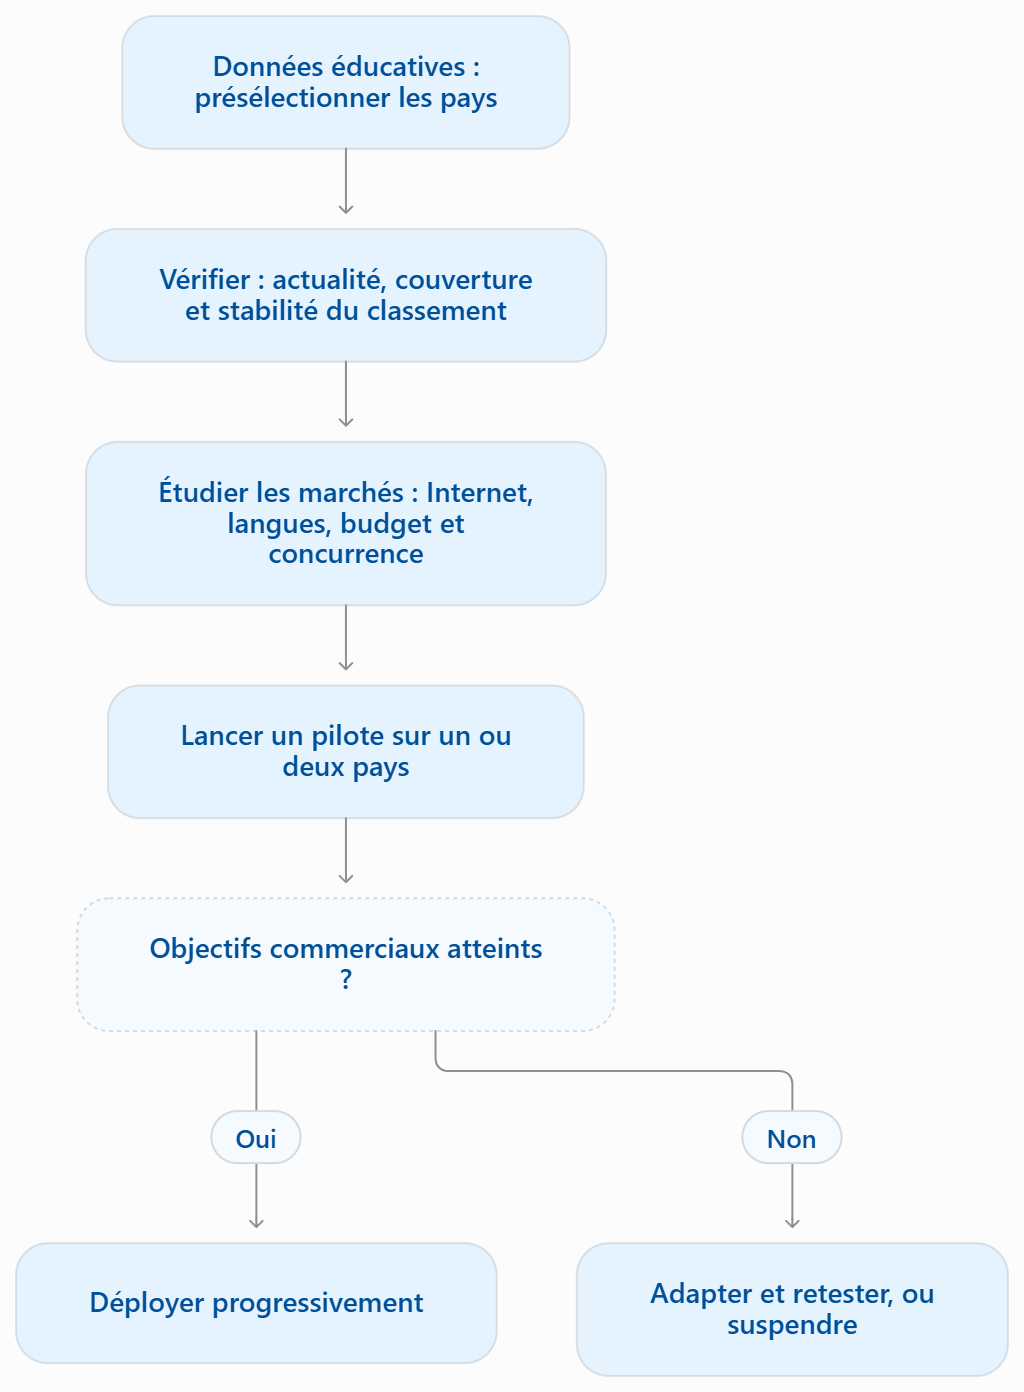

## **Message à Mark:**
- Les données permettent de choisir les marchés à explorer ; les études locales et le pilote doivent confirmer la décision d’implantation.

## **Bilan final:**

In [ ]:
# Bilan calculé pour la conclusion et la présentation : aucune liste de pays écrite à la main.
bilan_final = pd.DataFrame([
    {"Élément": "Années réellement agrégées", "Résultat": periode_analyse},
    {"Élément": "Statistique temporelle", "Résultat": statistique_agregation},
    {"Élément": "Indicateurs non redondants", "Résultat": len(indicateurs_conserves)},
    {"Élément": "Pays dans le pivot", "Résultat": len(pays_indicateurs)},
    {"Élément": "Pays complets comparés", "Résultat": len(pays_complets)},
    {"Élément": "Pays exclus du classement pour données manquantes", "Résultat": len(pays_exclus)},
    {"Élément": "Méthode de corrélation", "Résultat": methode_selection},
    {"Élément": "Corrélation maximale finale", "Résultat": correlation_max},
    {"Élément": "Pays à approfondir", "Résultat": ", ".join(pays_proposes["Country Name"])}
])
display(bilan_final)

print("Ces données permettent une présélection historique, à compléter par des informations "
      "récentes sur Internet, les langues, la concurrence et la capacité à payer.")

# Les commandes UV se lancent dans un terminal, pas comme des instructions Python.
# Ce diagnostic ne prétend pas avoir exécuté UV sur l'ordinateur de l'auteur.
import sys
from importlib.metadata import version
print("Interpréteur utilisé :", sys.executable)
for paquet in ["pandas", "numpy", "matplotlib", "seaborn", "scipy", "ipython"]:
    print(f"{paquet} : {version(paquet)}")
print("Vérification finale dans le dossier du projet : uv sync, puis uv run jupyter lab ; "
      "redémarrer le noyau et exécuter toutes les cellules.")
